# Universidad de Buenos Aires
# Aprendizaje Profundo - TP3
# Cohorte 26 - 4to bimestre 2026

## **Alumno 1:** Victoria Baiardo

## **Alumno 2:** Yonatan Aguirre

## **Alumno 3:** Francisco Facchini

# **CLASIFICADOR DE EMOCIONES**

El objetivo de este trabajo es construir una **red neuronal convolucional (CNN) en PyTorch, entrenada desde cero**, capaz de clasificar una imagen facial en una de 7 emociones: *alegría, disgusto, enojo, miedo, seriedad, sorpresa y tristeza*.

El notebook sigue el orden de la consigna:

0. Configuración y carga de datos.
1. **Preprocesamiento de datos** (análisis exploratorio y decisiones de preprocesamiento).
2. **Construcción y entrenamiento del modelo CNN.**
3. **Evaluación del modelo** (accuracy, F1 macro, loss, classification report y matrices de confusión).
4. **Prueba con imágenes nuevas.**
5. **Prueba con imágenes nuevas + detección y recorte de rostros.**

> **Nota sobre la ejecución:** el notebook corre tanto en Google Colab como en una PC local (Jupyter / VS Code). El dispositivo de cómputo (GPU de Apple `mps`, `cuda` o `cpu`) se detecta automáticamente. Todas las semillas están fijadas, aunque en GPU pueden existir pequeñas variaciones numéricas entre corridas.

## 0. Configuración y carga de datos

In [1]:
import os, sys, random, time, copy, re, unicodedata, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
import cv2
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning)
Image.MAX_IMAGE_PIXELS = None   # algunas fotos stock tienen más de 100 megapíxeles

# ---------------- Reproducibilidad y dispositivo ----------------
SEED = 42
def fijar_semilla(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
fijar_semilla()

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
IN_COLAB = "google.colab" in sys.modules

# ---------------- Estilo de gráficos ----------------
sns.set_theme(style="whitegrid", context="notebook")
COLOR_TRAIN = "#1f77b4"
COLOR_VAL = "#d62728"
COLOR_ACENTO = "#2a9d8f"

print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | Colab: {IN_COLAB}")

PyTorch 2.14.1 | dispositivo: mps | Colab: False


El dataset se encuentra en Google Drive (link de la consigna). Para que el notebook funcione en cualquier entorno, la celda siguiente **busca primero el dataset ya descargado** en la carpeta local `datos/dataset_emociones` (caso PC local) y, si no lo encuentra y estamos en Colab, lo descarga con `gdown` tal como sugiere la consigna.

In [2]:
def encontrar_dataset():
    candidatos = [Path("datos/dataset_emociones"), Path("TP3/datos/dataset_emociones"),
                  Path("../datos/dataset_emociones"), Path("/content/datos_zip/dataset_emociones")]
    for c in candidatos:
        if (c / "train").is_dir() and (c / "validation").is_dir():
            return c
    return None

raiz = encontrar_dataset()

if raiz is None and IN_COLAB:
    import gdown, zipfile
    url = "https://drive.google.com/uc?id=1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT"
    output = "archivo.zip"
    gdown.download(url, output, quiet=False)
    destino = "datos_zip"
    os.makedirs(destino, exist_ok=True)
    with zipfile.ZipFile(output, "r") as zip_ref:
        zip_ref.extractall(destino)
    raiz = Path("/content/datos_zip/dataset_emociones")

assert raiz is not None, ("No se encontró el dataset. Descomprimí dataset_emociones.zip dentro de la carpeta "
                          "'datos' (que quede datos/dataset_emociones/train y /validation).")

DATASET_ROOT_TRAIN = str(raiz / "train")
DATASET_ROOT_VAL = str(raiz / "validation")

CLASES = sorted(d for d in os.listdir(DATASET_ROOT_TRAIN) if os.path.isdir(os.path.join(DATASET_ROOT_TRAIN, d)))
print("Dataset en:", raiz.resolve())
print("Clases (orden alfabético = índice de clase):", dict(enumerate(CLASES)))

Dataset en: /Users/franciscofacchini/Downloads/Claudia - Li /8 - Aprendizaje Profundo/TP3/datos/dataset_emociones
Clases (orden alfabético = índice de clase): {0: 'alegria', 1: 'disgusto', 2: 'enojo', 3: 'miedo', 4: 'seriedad', 5: 'sorpresa', 6: 'tristeza'}


## 1. Preprocesamiento de Datos (2 puntos)

Antes de decidir qué preprocesamiento aplicar, analizamos el dataset: cuántas imágenes hay por emoción, cómo se ven, qué tamaño y formato tienen y cómo se distribuyen sus intensidades. Cada decisión de preprocesamiento posterior se apoya en una observación concreta de este análisis.

### 1.1 Distribución de clases

,train,validation,% train,% validation
clase,,,,
alegria,4772.0,1185.0,38.9,38.6
disgusto,717.0,160.0,5.8,5.2
enojo,705.0,162.0,5.7,5.3
miedo,281.0,74.0,2.3,2.4
seriedad,2524.0,680.0,20.6,22.2
sorpresa,1290.0,329.0,10.5,10.7
tristeza,1982.0,478.0,16.2,15.6
TOTAL,12271.0,3068.0,100.0,100.0


Razón entre la clase más y menos frecuente en train: 17.0 a 1


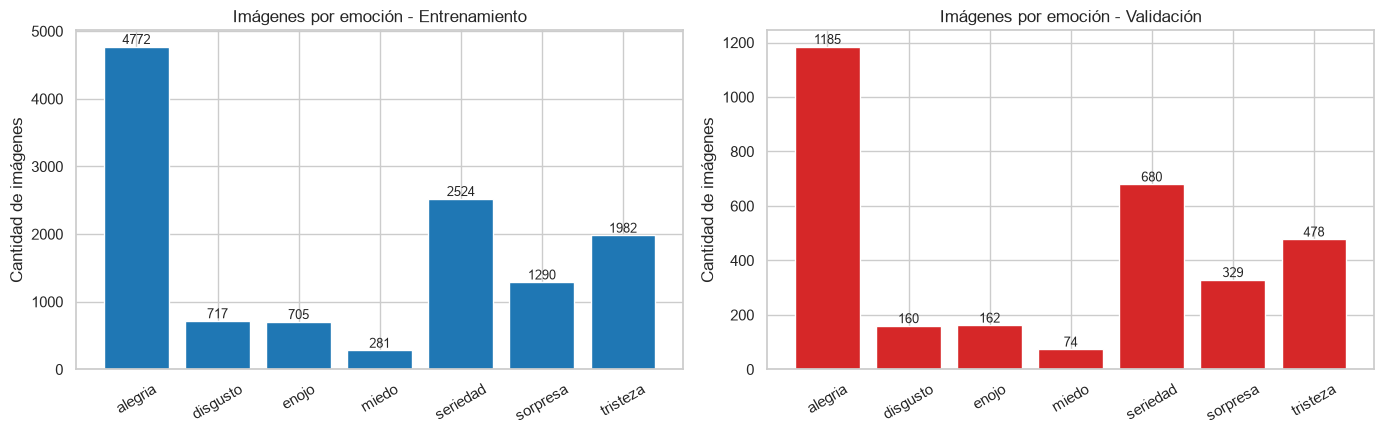

In [3]:
def listar_imagenes(root):
    filas = []
    for i, c in enumerate(CLASES):
        carpeta = os.path.join(root, c)
        for f in sorted(os.listdir(carpeta)):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                filas.append((os.path.join(carpeta, f), c, i))
    return pd.DataFrame(filas, columns=["ruta", "clase", "label"])

df_train = listar_imagenes(DATASET_ROOT_TRAIN)
df_val = listar_imagenes(DATASET_ROOT_VAL)

conteo = pd.DataFrame({"train": df_train["clase"].value_counts(),
                       "validation": df_val["clase"].value_counts()}).loc[CLASES]
conteo["% train"] = (100 * conteo["train"] / conteo["train"].sum()).round(1)
conteo["% validation"] = (100 * conteo["validation"] / conteo["validation"].sum()).round(1)
conteo.loc["TOTAL"] = [conteo["train"].sum(), conteo["validation"].sum(), 100.0, 100.0]
display(conteo)

ratio = conteo.loc[CLASES, "train"].max() / conteo.loc[CLASES, "train"].min()
print(f"Razón entre la clase más y menos frecuente en train: {ratio:.1f} a 1")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, color, titulo in zip(axes, ["train", "validation"], [COLOR_TRAIN, COLOR_VAL],
                                  ["Entrenamiento", "Validación"]):
    valores = conteo.loc[CLASES, col]
    barras = ax.bar(CLASES, valores, color=color)
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{int(v)}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Imágenes por emoción - {titulo}")
    ax.set_ylabel("Cantidad de imágenes")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Observación:** el dataset está **fuertemente desbalanceado**. En entrenamiento, *alegría* tiene 4.772 imágenes (38,9 %) y *miedo* solo 281 (2,3 %), una razón de casi 17 a 1; *disgusto* (717) y *enojo* (705) también tienen muy pocas. El conjunto de validación mantiene prácticamente las mismas proporciones, por lo que el desbalance es una característica del problema y no un accidente del *split*.

Esto tiene dos consecuencias que condicionan el resto del trabajo: (1) **accuracy no es una métrica suficiente**, porque un modelo que prediga siempre *alegría* ya obtendría alrededor de 39 % de accuracy sin aprender nada; por eso vamos a seguir también **F1 macro**, que pondera igual a todas las clases; y (2) hay que **compensar el desbalance durante el entrenamiento** para que las clases minoritarias (miedo, enojo, disgusto) no queden ignoradas por la red.

### 1.2 Cómo se ven las imágenes

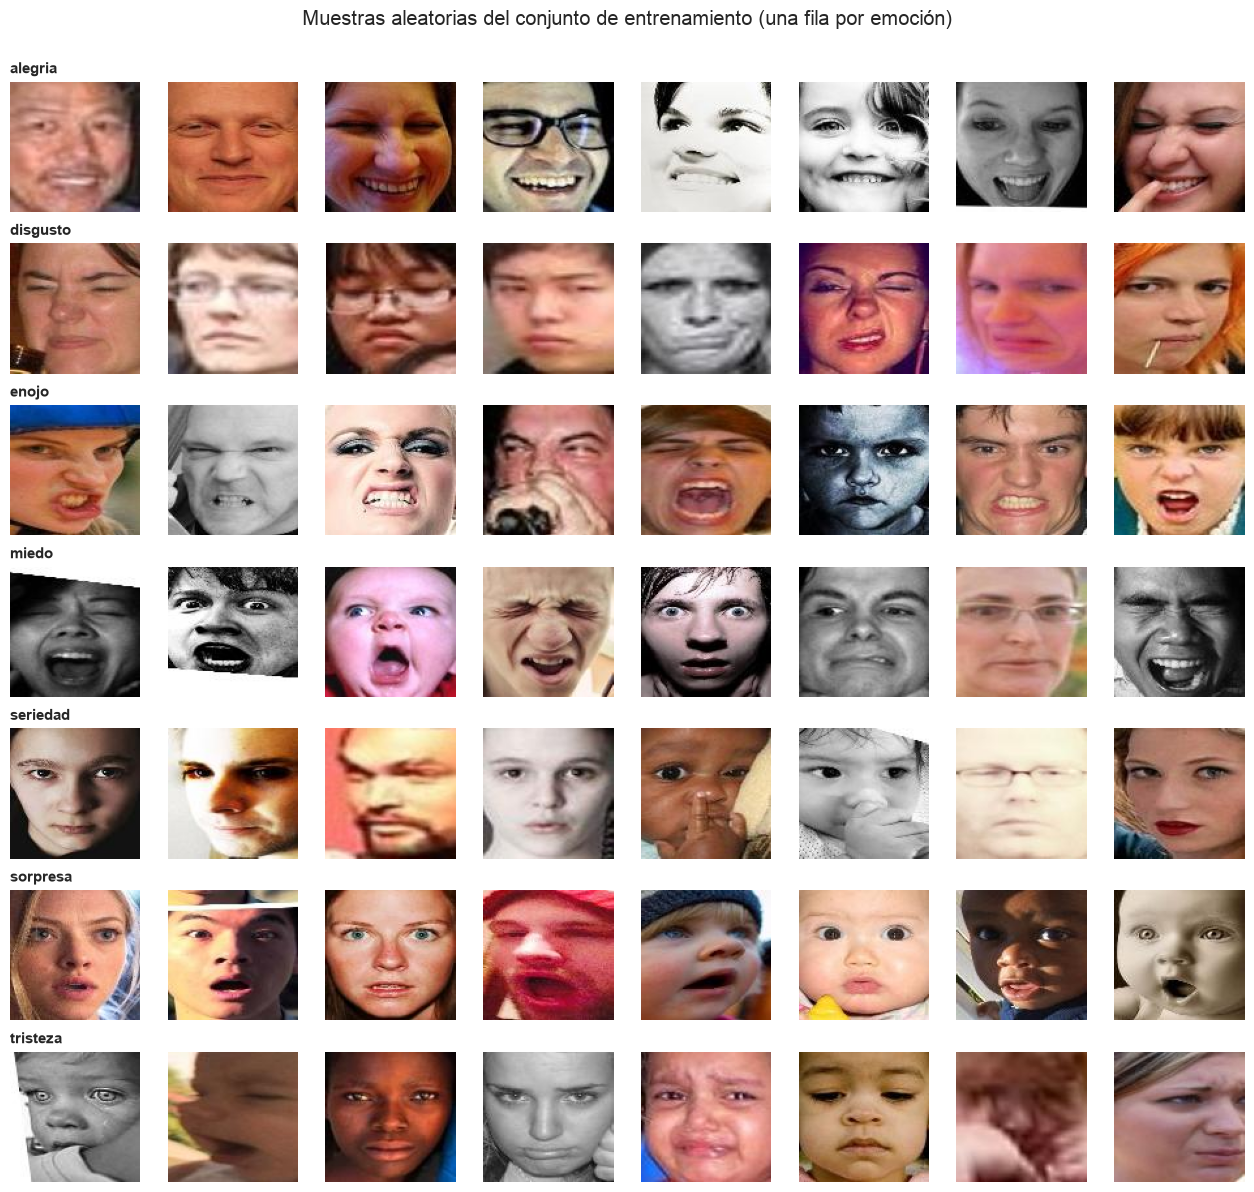

In [4]:
fijar_semilla()
N_POR_CLASE = 8
fig, axes = plt.subplots(len(CLASES), N_POR_CLASE, figsize=(N_POR_CLASE * 1.6, len(CLASES) * 1.7))
for fila, c in enumerate(CLASES):
    rutas = df_train[df_train["clase"] == c]["ruta"].sample(N_POR_CLASE, random_state=SEED).tolist()
    for col, r in enumerate(rutas):
        axes[fila, col].imshow(Image.open(r))
        axes[fila, col].axis("off")
        if col == 0:
            axes[fila, col].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Muestras aleatorias del conjunto de entrenamiento (una fila por emoción)", y=1.0)
plt.tight_layout()
plt.show()

### 1.3 Tamaño, formato y color

Tamaños (ancho, alto) en train: {(100, 100): 12271}
Modos de color en train: {'RGB': 12271}

Imágenes que en realidad son escala de grises (3 canales idénticos): 18.1 % de la muestra


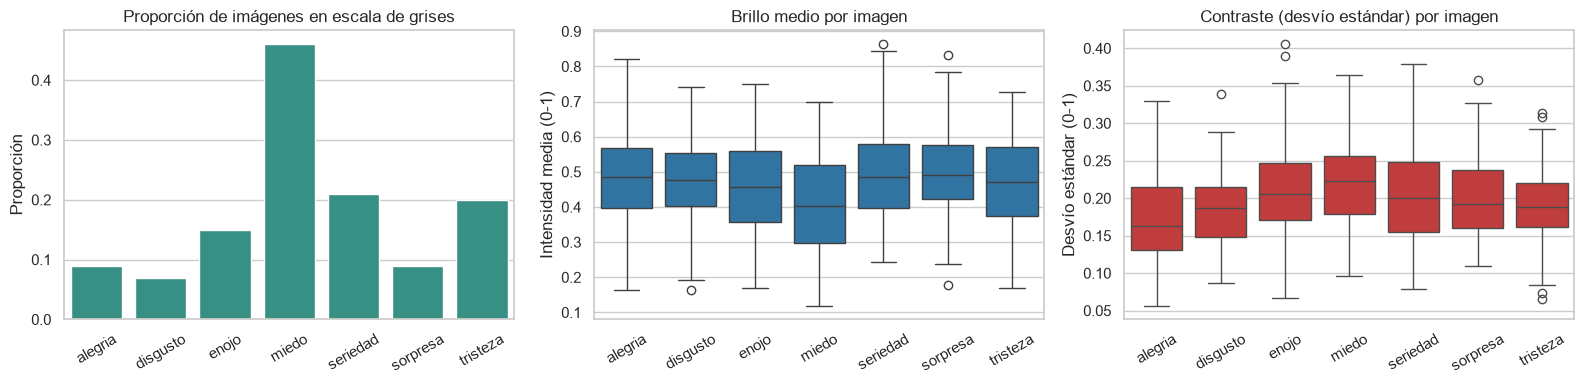

In [5]:
tamanios = Counter(); modos = Counter()
for r in df_train["ruta"]:
    with Image.open(r) as im:       # solo lee el encabezado, no decodifica los píxeles
        tamanios[im.size] += 1; modos[im.mode] += 1
print("Tamaños (ancho, alto) en train:", dict(tamanios))
print("Modos de color en train:", dict(modos))

# Muestra de 100 imágenes por clase para medir: ¿es realmente a color o es gris guardado como RGB?
fijar_semilla()
muestra = pd.concat([df_train[df_train["clase"] == c].sample(min(100, (df_train["clase"] == c).sum()), random_state=SEED)
                     for c in CLASES])
filas = []
for _, row in muestra.iterrows():
    a = np.asarray(Image.open(row["ruta"]).convert("RGB")).astype(np.float32)
    es_gris = np.abs(a[..., 0] - a[..., 1]).max() <= 2 and np.abs(a[..., 1] - a[..., 2]).max() <= 2
    g = a.mean(axis=2) / 255.0
    filas.append((row["clase"], es_gris, g.mean(), g.std()))
df_prop = pd.DataFrame(filas, columns=["clase", "es_gris", "brillo_medio", "contraste_std"])
df_prop["es_gris"] = df_prop["es_gris"].astype(float)

print(f"\nImágenes que en realidad son escala de grises (3 canales idénticos): "
      f"{100 * df_prop['es_gris'].mean():.1f} % de la muestra")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=df_prop, x="clase", y="es_gris", order=CLASES, color=COLOR_ACENTO, ax=axes[0], errorbar=None)
axes[0].set_title("Proporción de imágenes en escala de grises"); axes[0].set_ylabel("Proporción")
sns.boxplot(data=df_prop, x="clase", y="brillo_medio", order=CLASES, color=COLOR_TRAIN, ax=axes[1])
axes[1].set_title("Brillo medio por imagen"); axes[1].set_ylabel("Intensidad media (0-1)")
sns.boxplot(data=df_prop, x="clase", y="contraste_std", order=CLASES, color=COLOR_VAL, ax=axes[2])
axes[2].set_title("Contraste (desvío estándar) por imagen"); axes[2].set_ylabel("Desvío estándar (0-1)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30); ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Observación:** todas las imágenes son **cuadradas de 100×100 píxeles** y están guardadas como RGB, pero una parte importante de ellas (alrededor de una de cada cinco en la muestra) son en realidad **fotos en blanco y negro almacenadas con tres canales idénticos**, mientras que el resto es a color. Además, el brillo medio y el contraste varían bastante de una imagen a otra dentro de cada clase.

**Decisiones de preprocesamiento y su justificación:**

| Aspecto | Decisión | Justificación |
|---|---|---|
| **Tamaño** | Redimensionar a **64×64** | Las imágenes originales ya son pequeñas (100×100) y la expresión facial se define por rasgos globales (boca, cejas, ojos), no por detalles finos. 64×64 conserva esa información y reduce ~2,4 veces los píxeles, lo que acelera el entrenamiento y reduce el riesgo de sobreajuste. |
| **Relación de aspecto** | No requiere cambios en el dataset (todas son 1:1) | Las imágenes nuevas del punto 4 pueden tener cualquier relación de aspecto; ahí se discutirá el efecto de la deformación y por qué el recorte del punto 5 lo mitiga. |
| **Color vs. escala de grises** | Convertir a **escala de grises (1 canal)** | El color no es el factor que distingue una emoción (una cara de enojo lo es con cualquier tono de piel o iluminación). Como una parte del dataset ya es gris y otra a color, pasar todo a un único canal **unifica la distribución de entrada**, evita que la red aprenda atajos ligados al color y reduce parámetros. |
| **Normalización** | Estandarizar con la **media y el desvío del conjunto de entrenamiento** | Centra las entradas en torno a 0 con escala ~1, lo que estabiliza y acelera la convergencia del optimizador. Las estadísticas se calculan solo con *train* para no filtrar información de validación. |
| **Data augmentation** | Solo en *train*: volteo horizontal, rotación/traslación/escala leves, y variación de brillo y contraste | Una expresión facial es simétrica respecto del volteo horizontal y robusta a pequeñas rotaciones y desplazamientos. Como el brillo/contraste del dataset ya varía mucho, simularlo hace al modelo más robusto frente a las fotos nuevas del punto 4. No usamos transformaciones que alteren la expresión (por ejemplo, volteo vertical). |
| **Balanceo de datos** | **Pérdida con pesos por clase** (inverso de la raíz de la frecuencia) | Compensa el desbalance 17:1 sin descartar datos (*undersampling*) ni duplicar imágenes (*oversampling*). Usamos la raíz del inverso de la frecuencia, y no el inverso completo, para penalizar más los errores en clases minoritarias sin volver inestable el entrenamiento. |

### 1.4 Implementación del preprocesamiento

El preprocesamiento se divide en dos etapas: una **base determinística** (escala de grises y redimensionado), que es la misma para entrenamiento, validación e imágenes nuevas, y una **etapa final** que cambia según el caso: para *train* incluye el *data augmentation*, y para *validación* y para las imágenes nuevas solo convierte a tensor y normaliza.

In [6]:
IMG_SIZE = 64

# Etapa base (igual para train, validación e imágenes nuevas)
base_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
])

class EmocionesDataset(Dataset):
    """Carga y preprocesa (etapa base) todas las imágenes una sola vez en memoria; el
    augmentation se aplica al vuelo en __getitem__ únicamente si se pasa un transform."""
    def __init__(self, df, base_tf, transform=None):
        self.imgs = [base_tf(Image.open(r).convert("RGB")) for r in df["ruta"]]
        self.labels = df["label"].tolist()
        self.transform = transform
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        img = self.imgs[i]
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[i]

t0 = time.time()
train_ds = EmocionesDataset(df_train, base_tf)
val_ds = EmocionesDataset(df_val, base_tf)
print(f"Imágenes cargadas y preprocesadas (base) en {time.time() - t0:.1f} s: "
      f"{len(train_ds)} train, {len(val_ds)} validación")

# Estadísticas de normalización: SOLO con el conjunto de entrenamiento
pix = np.stack([np.asarray(im) for im in train_ds.imgs]).astype(np.float32) / 255.0
MEDIA, DESVIO = float(pix.mean()), float(pix.std())
del pix
print(f"Media de train = {MEDIA:.4f} | Desvío de train = {DESVIO:.4f}")

# Etapa final
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize([MEDIA], [DESVIO]),
])
eval_tf = transforms.Compose([                 # validación e imágenes nuevas
    transforms.ToTensor(),
    transforms.Normalize([MEDIA], [DESVIO]),
])
train_ds.transform = train_tf
val_ds.transform = eval_tf

def desnormalizar(t):
    return (t * DESVIO + MEDIA).clamp(0, 1)

# Pesos por clase (inverso de la raíz de la frecuencia, normalizado para que promedien ~1)
conteos = np.bincount(df_train["label"], minlength=len(CLASES))
pesos = (conteos.sum() / (len(CLASES) * conteos)) ** 0.5
pesos = pesos / pesos.mean()
class_weights = torch.tensor(pesos, dtype=torch.float32)
display(pd.DataFrame({"imágenes train": conteos, "peso en la loss": pesos.round(3)}, index=CLASES))

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Lotes por época: {len(train_loader)} (train) | {len(val_loader)} (validación)")

Imágenes cargadas y preprocesadas (base) en 1.5 s: 12271 train, 3068 validación
Media de train = 0.4816 | Desvío de train = 0.2389


,imágenes train,peso en la loss
alegria,4772,0.462
disgusto,717,1.192
enojo,705,1.202
miedo,281,1.904
seriedad,2524,0.635
sorpresa,1290,0.889
tristeza,1982,0.717


Lotes por época: 192 (train) | 48 (validación)


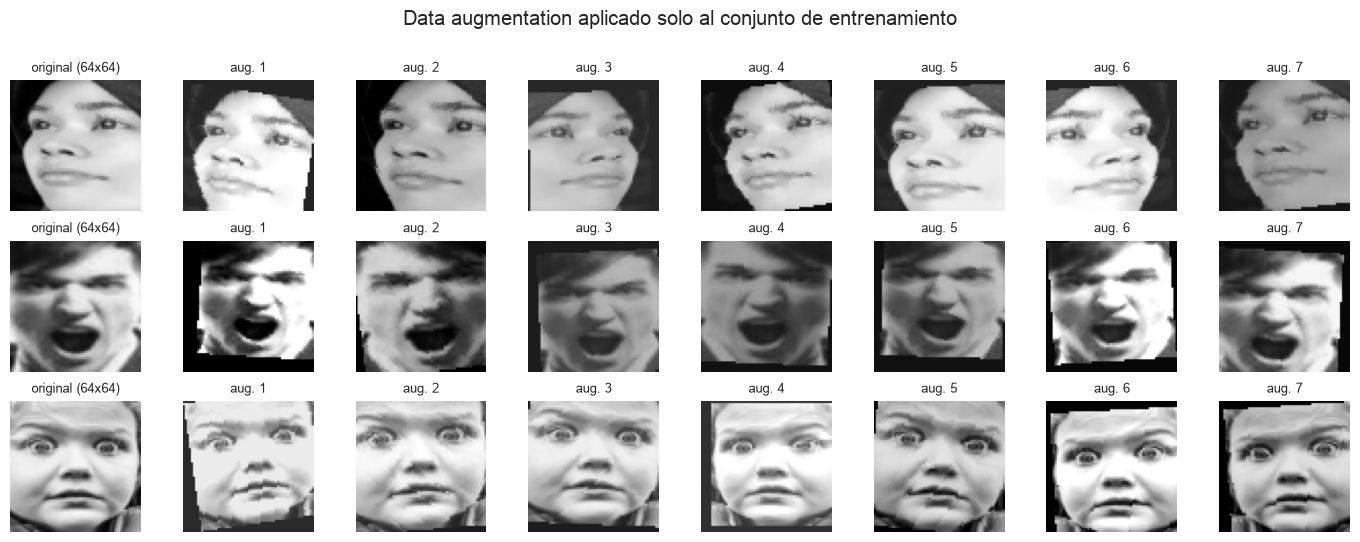

In [7]:
# Visualización del augmentation: la misma imagen original con 7 transformaciones aleatorias distintas
fijar_semilla()
ejemplos = [df_train[df_train["clase"] == c].index[0] for c in ["alegria", "enojo", "sorpresa"]]
fig, axes = plt.subplots(len(ejemplos), 8, figsize=(14, 5.4))
for fila, idx in enumerate(ejemplos):
    base = train_ds.imgs[idx]
    axes[fila, 0].imshow(base, cmap="gray", vmin=0, vmax=255)
    axes[fila, 0].set_title("original (64x64)", fontsize=9)
    for col in range(1, 8):
        t = train_tf(base)
        axes[fila, col].imshow(desnormalizar(t)[0], cmap="gray", vmin=0, vmax=1)
        axes[fila, col].set_title(f"aug. {col}", fontsize=9)
    for ax in axes[fila]:
        ax.axis("off")
plt.suptitle("Data augmentation aplicado solo al conjunto de entrenamiento", y=1.0)
plt.tight_layout()
plt.show()

**Observación:** las imágenes aumentadas conservan claramente la expresión original (la boca, las cejas y los ojos siguen siendo reconocibles), pero varían en posición, inclinación, orientación e iluminación. Esa es justamente la variación que esperamos encontrar en fotos nuevas, por lo que el *augmentation* añade diversidad útil sin cambiar la etiqueta. El conjunto de validación y las imágenes nuevas **no** se aumentan: solo reciben la etapa base y la normalización.

---
## 2. Construcción y entrenamiento del Modelo CNN (3.5 puntos)

### 2.1 Arquitectura y justificación

La entrada es un tensor de **1×64×64**. Diseñamos una CNN de **cuatro bloques convolucionales** seguida de un clasificador totalmente conectado:

* **Bloque convolucional** = `Conv 3×3 → BatchNorm → ReLU → Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2 → Dropout2d`.
* **Cantidad de filtros 32 → 64 → 128 → 256:** el número de canales se duplica cada vez que el *pooling* reduce a la mitad la resolución espacial (64→32→16→8→4). Las primeras capas detectan rasgos simples (bordes, contornos) y las últimas combinan rasgos en patrones más complejos (forma de la boca, arqueo de las cejas).
* **Kernels de 3×3 apilados de a dos:** dos convoluciones 3×3 seguidas tienen el mismo campo receptivo que una de 5×5 pero con menos parámetros y una no linealidad extra. Con `padding=1` se conserva el tamaño espacial dentro del bloque y solo el *pooling* lo reduce.
* **Activación ReLU en las capas ocultas:** es barata, no se satura para valores positivos (evita el *vanishing gradient*) y es el estándar en CNN. **La capa de salida no lleva activación**: entrega *logits*, porque la función de costo `CrossEntropyLoss` aplica internamente `log-softmax`, que es numéricamente más estable que aplicar `softmax` por separado. La probabilidad por clase (`softmax`) solo se calcula al momento de inferir.
* **Batch Normalization:** estabiliza y acelera el entrenamiento y permite usar un learning rate más alto.
* **Regularización:** `Dropout2d` (0,1 → 0,2) en los bloques y `Dropout` de 0,5 antes de la capa final, además del *augmentation* y de un pequeño *weight decay*. El dataset tiene ~12 mil imágenes y la red ~2 millones de parámetros, por lo que el riesgo de sobreajuste es real.
* **Clasificador:** se aplanan los mapas de 256×4×4 y se pasan por una capa densa de 256 neuronas con ReLU y una capa de salida de 7 neuronas (una por emoción).

### 2.2 Función de costo, optimizador y learning rate

* **Función de costo:** `CrossEntropyLoss` con **pesos por clase** (sección 1.4), la elección natural para clasificación multiclase con clases excluyentes y la forma de compensar el desbalance.
* **Optimizador:** **Adam** con `lr = 1e-3` y `weight_decay = 1e-4`. Adam adapta el paso de cada parámetro y converge de forma robusta con poca puesta a punto; 1e-3 es el valor de referencia para Adam y, combinado con *BatchNorm*, resulta estable.
* **Scheduler:** `ReduceLROnPlateau` que **reduce a la mitad el learning rate** cuando el F1 macro de validación no mejora durante 3 épocas, para refinar la solución una vez que el aprendizaje se estanca.
* **Selección del modelo:** se entrena hasta 80 épocas con **early stopping** (se detiene tras 10 épocas sin mejorar el F1 macro de validación) y nos quedamos con los pesos de la **mejor época según F1 macro de validación**, porque es la métrica que mejor refleja el desempeño en todas las clases.

In [8]:
class BloqueConv(nn.Module):
    def __init__(self, c_in, c_out, p_drop):
        super().__init__()
        self.bloque = nn.Sequential(
            nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(p_drop),
        )
    def forward(self, x):
        return self.bloque(x)

class EmotionCNN(nn.Module):
    def __init__(self, n_clases=7):
        super().__init__()
        self.features = nn.Sequential(
            BloqueConv(1, 32, 0.10),     # 64 -> 32
            BloqueConv(32, 64, 0.10),    # 32 -> 16
            BloqueConv(64, 128, 0.20),   # 16 -> 8
            BloqueConv(128, 256, 0.20),  # 8  -> 4
        )
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, n_clases),    # logits (sin softmax: lo aplica CrossEntropyLoss)
        )
    def forward(self, x):
        return self.clasificador(self.features(x))

fijar_semilla()
modelo = EmotionCNN(n_clases=len(CLASES)).to(DEVICE)
n_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(modelo)
print(f"\nParámetros entrenables: {n_params:,}")

# Chequeo de dimensiones con un lote de prueba
x_demo, y_demo = next(iter(train_loader))
print("Lote de entrada:", tuple(x_demo.shape), "-> salida:", tuple(modelo(x_demo.to(DEVICE)).shape))

EmotionCNN(
  (features): Sequential(
    (0): BloqueConv(
      (bloque): Sequential(
        (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.1, inplace=False)
      )
    )
    (1): BloqueConv(
      (bloque): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_si

### 2.3 Entrenamiento

En cada época se calculan **loss, accuracy y F1 macro** tanto para entrenamiento como para validación, de modo de poder graficar su evolución en la sección 3. Las métricas de *train* se calculan durante el propio entrenamiento (con *dropout* activo y datos aumentados), por lo que suelen ser algo más pesimistas que las de validación al comienzo.

In [9]:
EPOCAS = 80
LR = 1e-3
WEIGHT_DECAY = 1e-4
PACIENCIA_ES = 10      # early stopping
PACIENCIA_LR = 3       # ReduceLROnPlateau

criterio = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
optimizador = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="max", factor=0.5, patience=PACIENCIA_LR)

def correr_epoca(modelo, loader, criterio, optimizador=None):
    entrenando = optimizador is not None
    modelo.train(entrenando)
    loss_total, n = 0.0, 0
    preds, reales = [], []
    with torch.set_grad_enabled(entrenando):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            salida = modelo(x)
            loss = criterio(salida, y)
            if entrenando:
                optimizador.zero_grad()
                loss.backward()
                optimizador.step()
            loss_total += loss.item() * x.size(0)
            n += x.size(0)
            preds.append(salida.argmax(1).cpu())
            reales.append(y.cpu())
    preds = torch.cat(preds).numpy(); reales = torch.cat(reales).numpy()
    return loss_total / n, accuracy_score(reales, preds), f1_score(reales, preds, average="macro")

historia = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "train_f1", "val_f1", "lr"]}
mejor_f1, mejor_epoca, mejores_pesos, sin_mejora = -1.0, 0, None, 0

fijar_semilla()
t_inicio = time.time()
for epoca in range(1, EPOCAS + 1):
    t_ep = time.time()
    tr_loss, tr_acc, tr_f1 = correr_epoca(modelo, train_loader, criterio, optimizador)
    va_loss, va_acc, va_f1 = correr_epoca(modelo, val_loader, criterio)
    scheduler.step(va_f1)

    for k, v in zip(historia.keys(), [tr_loss, va_loss, tr_acc, va_acc, tr_f1, va_f1, optimizador.param_groups[0]["lr"]]):
        historia[k].append(v)

    marca = ""
    if va_f1 > mejor_f1:
        mejor_f1, mejor_epoca, sin_mejora = va_f1, epoca, 0
        mejores_pesos = copy.deepcopy(modelo.state_dict())
        marca = "  <- mejor"
    else:
        sin_mejora += 1

    print(f"Época {epoca:02d}/{EPOCAS} | loss {tr_loss:.4f}/{va_loss:.4f} | acc {tr_acc:.3f}/{va_acc:.3f} | "
          f"F1 {tr_f1:.3f}/{va_f1:.3f} | lr {optimizador.param_groups[0]['lr']:.1e} | {time.time() - t_ep:.0f}s{marca}")

    if sin_mejora >= PACIENCIA_ES:
        print(f"\nEarly stopping en la época {epoca}: {PACIENCIA_ES} épocas sin mejorar el F1 macro de validación.")
        break

print(f"\nEntrenamiento finalizado en {(time.time() - t_inicio) / 60:.1f} min. "
      f"Mejor época: {mejor_epoca} (F1 macro de validación = {mejor_f1:.4f})")
modelo.load_state_dict(mejores_pesos)
torch.save(mejores_pesos, "modelo_emociones_cnn.pt")

Época 01/80 | loss 1.9237/1.7516 | acc 0.345/0.360 | F1 0.134/0.098 | lr 1.0e-03 | 15s  <- mejor
Época 02/80 | loss 1.8522/1.6236 | acc 0.369/0.383 | F1 0.113/0.081 | lr 1.0e-03 | 15s
Época 03/80 | loss 1.8389/1.7336 | acc 0.373/0.386 | F1 0.103/0.080 | lr 1.0e-03 | 15s
Época 04/80 | loss 1.8405/1.6827 | acc 0.388/0.386 | F1 0.080/0.080 | lr 1.0e-03 | 15s
Época 05/80 | loss 1.8274/1.6826 | acc 0.387/0.386 | F1 0.084/0.080 | lr 5.0e-04 | 15s
Época 06/80 | loss 1.8158/1.6226 | acc 0.388/0.387 | F1 0.081/0.080 | lr 5.0e-04 | 15s
Época 07/80 | loss 1.8128/1.6461 | acc 0.379/0.391 | F1 0.112/0.100 | lr 5.0e-04 | 16s  <- mejor
Época 08/80 | loss 1.8090/1.6542 | acc 0.385/0.391 | F1 0.120/0.112 | lr 5.0e-04 | 15s  <- mejor
Época 09/80 | loss 1.8038/1.5826 | acc 0.380/0.404 | F1 0.132/0.142 | lr 5.0e-04 | 15s  <- mejor
Época 10/80 | loss 1.7789/1.5026 | acc 0.388/0.413 | F1 0.144/0.162 | lr 5.0e-04 | 15s  <- mejor
Época 11/80 | loss 1.7251/1.4373 | acc 0.407/0.467 | F1 0.174/0.231 | lr 5.0e-04

---
## 3. Evaluación del Modelo (2.5 puntos)

Todas las métricas finales se calculan sobre el conjunto de **validación**, con el modelo de la **mejor época** (según F1 macro).

### 3.1 Evolución por época: accuracy, F1 macro y loss

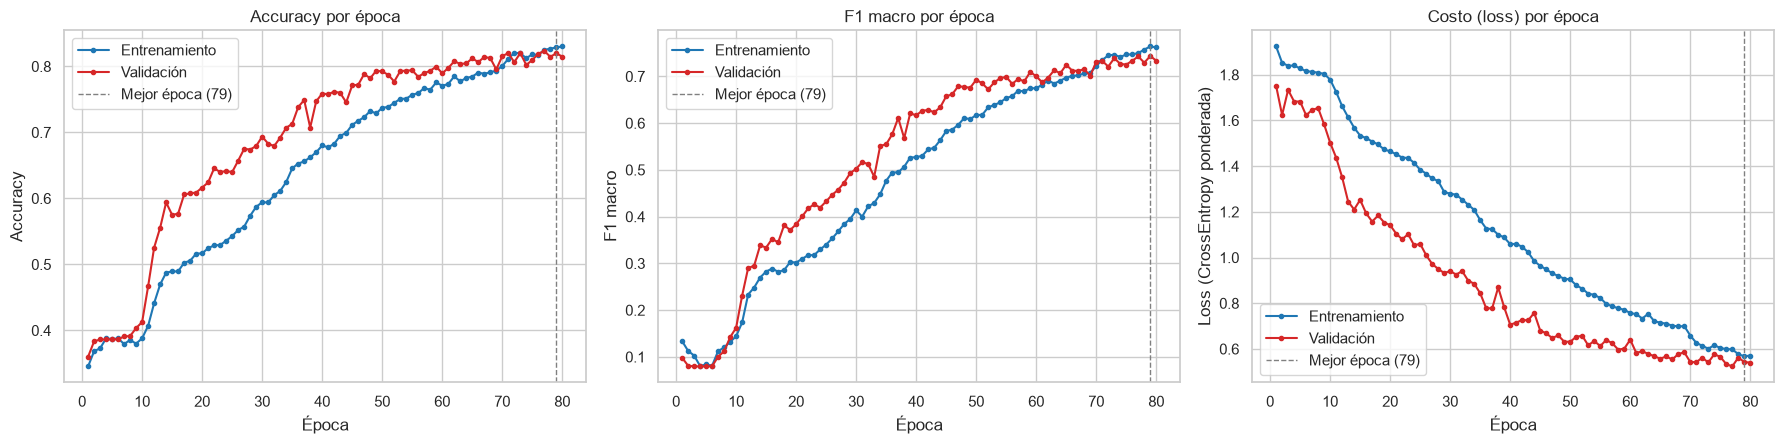

In [10]:
epocas = np.arange(1, len(historia["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, (k, titulo, ylabel) in zip(axes, [("acc", "Accuracy por época", "Accuracy"),
                                          ("f1", "F1 macro por época", "F1 macro"),
                                          ("loss", "Costo (loss) por época", "Loss (CrossEntropy ponderada)")]):
    ax.plot(epocas, historia[f"train_{k}"], color=COLOR_TRAIN, marker="o", ms=3, label="Entrenamiento")
    ax.plot(epocas, historia[f"val_{k}"], color=COLOR_VAL, marker="o", ms=3, label="Validación")
    ax.axvline(mejor_epoca, color="gray", ls="--", lw=1, label=f"Mejor época ({mejor_epoca})")
    ax.set_title(titulo); ax.set_xlabel("Época"); ax.set_ylabel(ylabel); ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Métricas finales sobre validación

In [11]:
@torch.no_grad()
def predecir_loader(modelo, loader):
    modelo.eval()
    reales, preds, probs = [], [], []
    for x, y in loader:
        p = F.softmax(modelo(x.to(DEVICE)), dim=1).cpu()
        probs.append(p); preds.append(p.argmax(1)); reales.append(y)
    return torch.cat(reales).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy()

y_true, y_pred, y_prob = predecir_loader(modelo, val_loader)
acc_final = accuracy_score(y_true, y_pred)
f1_final = f1_score(y_true, y_pred, average="macro")
print(f"Accuracy final en validación : {acc_final:.4f}  ({100 * acc_final:.1f} %)")
print(f"F1 macro final en validación : {f1_final:.4f}")
print(f"Referencia: un modelo que siempre predice la clase mayoritaria obtendría "
      f"{100 * conteo.loc['alegria', 'validation'] / conteo.loc['TOTAL', 'validation']:.1f} % de accuracy.\n")

print("Classification report (validación):\n")
print(classification_report(y_true, y_pred, target_names=CLASES, digits=3))

Accuracy final en validación : 0.8198  (82.0 %)
F1 macro final en validación : 0.7436
Referencia: un modelo que siempre predice la clase mayoritaria obtendría 38.6 % de accuracy.

Classification report (validación):

              precision    recall  f1-score   support

     alegria      0.947     0.913     0.930      1185
    disgusto      0.400     0.625     0.488       160
       enojo      0.765     0.704     0.733       162
       miedo      0.657     0.622     0.639        74
    seriedad      0.808     0.753     0.779       680
    sorpresa      0.848     0.863     0.855       329
    tristeza      0.774     0.789     0.781       478

    accuracy                          0.820      3068
   macro avg      0.743     0.753     0.744      3068
weighted avg      0.833     0.820     0.825      3068



### 3.3 Matrices de confusión

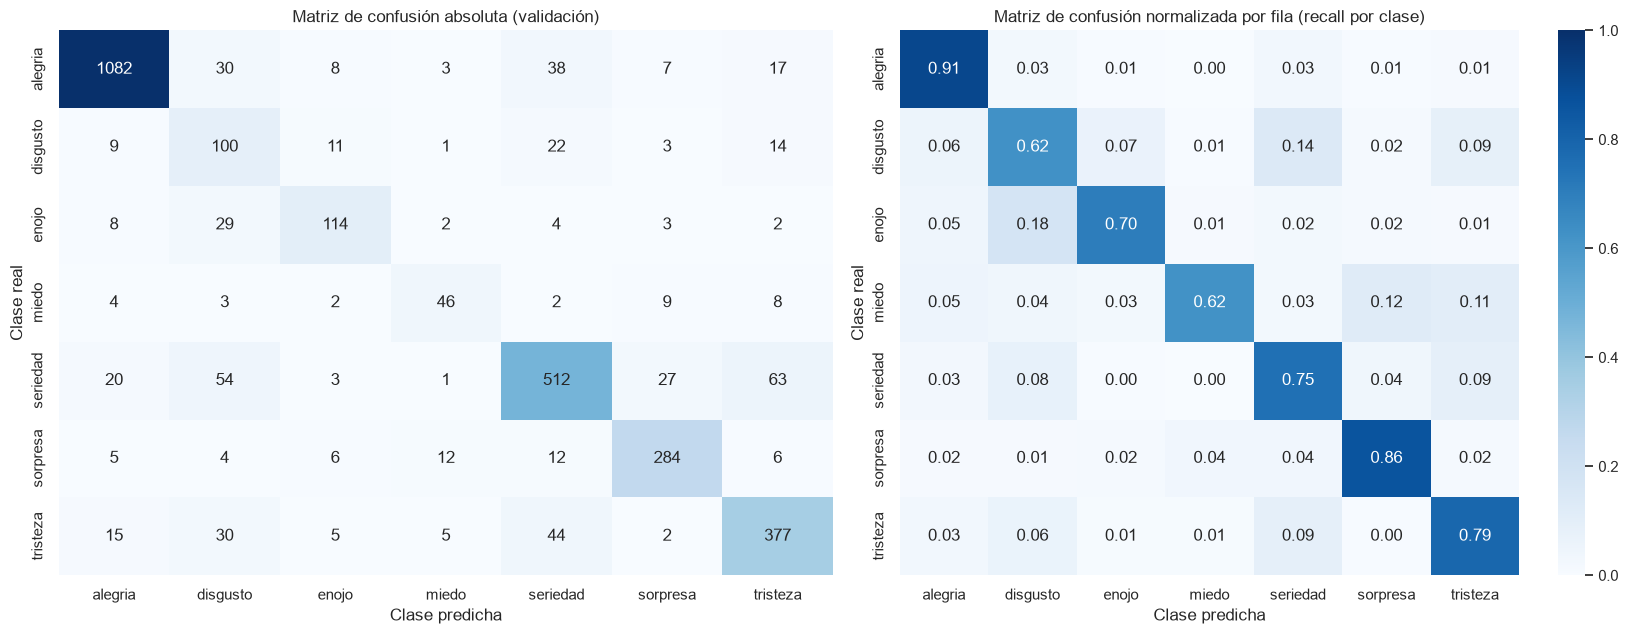

,clase real,predicha como,cantidad,% de la clase real
0,seriedad,tristeza,63,0.093
1,seriedad,disgusto,54,0.079
2,tristeza,seriedad,44,0.092
3,alegria,seriedad,38,0.032
4,alegria,disgusto,30,0.025
5,tristeza,disgusto,30,0.063
6,enojo,disgusto,29,0.179
7,seriedad,sorpresa,27,0.040


In [12]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = confusion_matrix(y_true, y_pred, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=axes[0], cbar=False)
axes[0].set_title("Matriz de confusión absoluta (validación)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASES, yticklabels=CLASES, ax=axes[1])
axes[1].set_title("Matriz de confusión normalizada por fila (recall por clase)")
for ax in axes:
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

# Pares de emociones más confundidos (fuera de la diagonal)
pares = [(CLASES[i], CLASES[j], int(cm[i, j]), cm_norm[i, j]) for i in range(len(CLASES)) for j in range(len(CLASES)) if i != j]
display(pd.DataFrame(sorted(pares, key=lambda t: -t[2])[:8], columns=["clase real", "predicha como", "cantidad", "% de la clase real"]).round(3))

### 3.4 Observaciones y conclusiones de la evaluación

**Resultado global.** El modelo de la mejor época (la 79 de 80) alcanza **82,0 % de accuracy** y un **F1 macro de 0,744** sobre validación, frente a un 38,6 % de accuracy que lograría un clasificador que siempre responde *alegría*. La distancia entre accuracy (0,82) y F1 macro (0,74) confirma lo anticipado en la sección 1: las clases minoritarias son más difíciles que las mayoritarias y por eso conviene seguir ambas métricas.

**Dinámica de entrenamiento.** Las curvas muestran dos fases bien distintas. Durante las primeras 6 épocas la red casi no aprende: el F1 macro de validación se queda en torno a 0,08 y el accuracy en 0,386, que es exactamente la proporción de *alegría* en validación, es decir que el modelo predecía una única clase. Entre las épocas 7 y 10 empieza a salir de ese estado y desde la 10 la pérdida de validación baja de forma sostenida: el F1 macro sube de 0,16 (época 10) a 0,62 (época 39) y a 0,74 (época 79). El scheduler redujo el learning rate de 1e-3 a 5e-4 en la época 5 y a 2,5e-4 en la 69. Una primera corrida de 40 épocas terminó con la red todavía mejorando (F1 macro de 0,62 y accuracy de 74,7 %), por lo que ampliamos el límite a 80 épocas; el *early stopping* nunca se activó, lo que indica que el modelo siguió ganando algo hasta el final, aunque ya con rendimientos decrecientes.

**¿Hay sobreajuste?** Durante casi todo el entrenamiento las métricas de *train* están por debajo de las de validación. Esto es esperable: se miden con *dropout* activo y sobre imágenes aumentadas, es decir, en condiciones más difíciles que las de validación. Recién hacia el final (épocas 71 a 80) las curvas se cruzan y *train* supera levemente a validación (en la época 80: accuracy 0,830 contra 0,815 y F1 macro 0,762 contra 0,733), mientras la loss de validación se estabiliza en torno a 0,54. Es una señal incipiente de sobreajuste, todavía moderada, que justifica no seguir entrenando mucho más y respalda el uso de regularización (*dropout*, *weight decay* y *augmentation*). Cabe aclarar que la mejor época se eligió mirando el propio conjunto de validación, por lo que las métricas de validación son levemente optimistas respecto de un conjunto de test independiente, que la consigna no provee.

**Desempeño por clase.** *Alegría* es la mejor clasificada (F1 0,93), seguida por *sorpresa* (0,86), *tristeza* (0,78), *seriedad* (0,78) y *enojo* (0,73). *Miedo* llega a 0,64 pese a tener solo 281 imágenes de entrenamiento (2,3 %), lo que sugiere que los pesos por clase y el *augmentation* cumplieron su función. *Disgusto* es la clase más débil (F1 0,49) y muestra el efecto secundario del balanceo: su *recall* es alto (0,63) pero su *precision* es de solo 0,40, porque la red, al penalizarse más los errores en esta clase, la predice con frecuencia sobre imágenes de otras emociones (de las 250 imágenes que el modelo etiqueta como *disgusto*, solo 100 lo son). Es el costo típico de compensar un desbalance: se gana *recall* en las clases minoritarias a cambio de *precision*.

**Confusiones más frecuentes.** Casi todos los errores ocurren entre emociones con rasgos faciales parecidos o de baja intensidad: *seriedad* se confunde con *tristeza* (63 casos) y con *disgusto* (54), y *tristeza* con *seriedad* (44); un 18 % de los *enojo* se predicen como *disgusto* (ambos fruncen el ceño y tensan la cara), un 14 % de los *disgusto* como *seriedad*, y *miedo* se confunde con *sorpresa* (12 %) y con *tristeza* (11 %), emociones que comparten ojos muy abiertos o cejas elevadas. *Seriedad* funciona además como clase "refugio": al ser la expresión neutra y la segunda más numerosa, absorbe las expresiones suaves o ambiguas de otras clases. Estas confusiones son semánticamente razonables, lo que indica que la red aprendió rasgos faciales con sentido, y no atajos espurios.

---
## 4. Prueba de Imágenes Nuevas (1 punto)

Probamos el modelo con **imágenes sueltas** (fotos stock de internet de uso libre, bajadas de sitios como Pexels, Unsplash y Pixabay) que **no pertenecen** al dataset de entrenamiento ni al de validación. Hay al menos una imagen por emoción y varias tienen distinta relación de aspecto y tamaño (algunas superan los 100 megapíxeles).

La emoción esperada de cada imagen se toma del **nombre del archivo** (por ejemplo, `tristeza 2.jpg` es *tristeza*; los archivos `neutral` se consideran *seriedad*).

### 4.1 Carga de las imágenes

In [13]:
def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c)).lower()

ALIAS_EMOCION = {"neutral": "seriedad", "serio": "seriedad", "seria": "seriedad", "felicidad": "alegria",
                 "feliz": "alegria", "asco": "disgusto", "ira": "enojo", "enojado": "enojo", "susto": "miedo"}

def emocion_desde_nombre(nombre_archivo):
    base = sin_tildes(Path(nombre_archivo).stem)
    palabra = re.sub(r"[^a-z]+", " ", base).split()[0]
    return ALIAS_EMOCION.get(palabra, palabra)

def encontrar_carpeta_imagenes():
    for datos in [Path("datos"), Path("TP3/datos"), Path("../datos"), Path("/content")]:
        if datos.is_dir():
            for d in datos.iterdir():
                if d.is_dir() and sin_tildes(d.name).replace("_", " ") == "imagenes nuevas":
                    return d
    return None

carpeta_img = encontrar_carpeta_imagenes()
if carpeta_img is None and IN_COLAB:
    from google.colab import files
    carpeta_img = Path("/content/imagenes_nuevas"); carpeta_img.mkdir(exist_ok=True)
    print("Subí las imágenes nuevas (una o más por emoción):")
    for nombre, contenido in files.upload().items():
        (carpeta_img / nombre).write_bytes(contenido)
assert carpeta_img is not None, "No se encontró la carpeta 'imágenes nuevas' dentro de 'datos'."

def cargar_imagen(ruta, lado_max=1024):
    """Abre la foto respetando la orientación EXIF y la reduce (máx. 1024 px de lado) para poder
    manejar fotos de más de 100 megapíxeles. El modo draft de JPEG evita decodificar todos los píxeles."""
    im = Image.open(ruta)
    im.draft("RGB", (lado_max, lado_max))
    im = ImageOps.exif_transpose(im).convert("RGB")
    im.thumbnail((lado_max, lado_max))
    return im

rutas_nuevas = sorted(p for p in carpeta_img.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png", ".webp"))
imagenes_nuevas = []
for p in rutas_nuevas:
    esperada = emocion_desde_nombre(p.name)
    assert esperada in CLASES, f"No pude deducir la emoción de '{p.name}' (obtuve '{esperada}')."
    with Image.open(p) as im0:
        tam_original = im0.size
    imagenes_nuevas.append({"archivo": p.name, "esperada": esperada, "imagen": cargar_imagen(p), "tam_original": tam_original})

resumen = pd.DataFrame([{"archivo": d["archivo"], "emoción esperada": d["esperada"],
                         "tamaño original (px)": f"{d['tam_original'][0]}x{d['tam_original'][1]}"} for d in imagenes_nuevas])
display(resumen)
cobertura = Counter(d["esperada"] for d in imagenes_nuevas)
print(f"\nTotal de imágenes nuevas: {len(imagenes_nuevas)} | Imágenes por emoción: {dict(cobertura)}")
faltan = [c for c in CLASES if c not in cobertura]
assert len(imagenes_nuevas) >= 12 and not faltan, f"La consigna exige >= 12 imágenes y las 7 emociones. Faltan: {faltan}"

,archivo,emoción esperada,tamaño original (px)
0,alegria 1.jpg,alegria,3648x5472
1,alegría 2.jpg,alegria,3321x4982
2,disgusto 1.jpg,disgusto,3456x5184
3,disgusto 2.jpg,disgusto,5760x3825
4,disgusto 3.jpg,disgusto,4309x4309
5,enojo 1.jpg,enojo,2965x4448
6,enojo 2.jpg,enojo,8192x5464
7,enojo 4.jpg,enojo,9238x13948
8,miedo 1.jpg,miedo,5910x6000
9,miedo 2.jpg,miedo,5472x3648



Total de imágenes nuevas: 17 | Imágenes por emoción: {'alegria': 2, 'disgusto': 3, 'enojo': 3, 'miedo': 2, 'seriedad': 3, 'sorpresa': 2, 'tristeza': 2}


### 4.2 Predicción con el mismo preprocesamiento de validación

Cada imagen pasa por **exactamente las mismas transformaciones que el conjunto de validación** (`base_tf` + `eval_tf`: escala de grises, redimensionado a 64×64, conversión a tensor y normalización). Para cada una se muestra la imagen original, la imagen ya preprocesada tal como la ve la red, el score (probabilidad *softmax*) de cada clase y la clase ganadora.

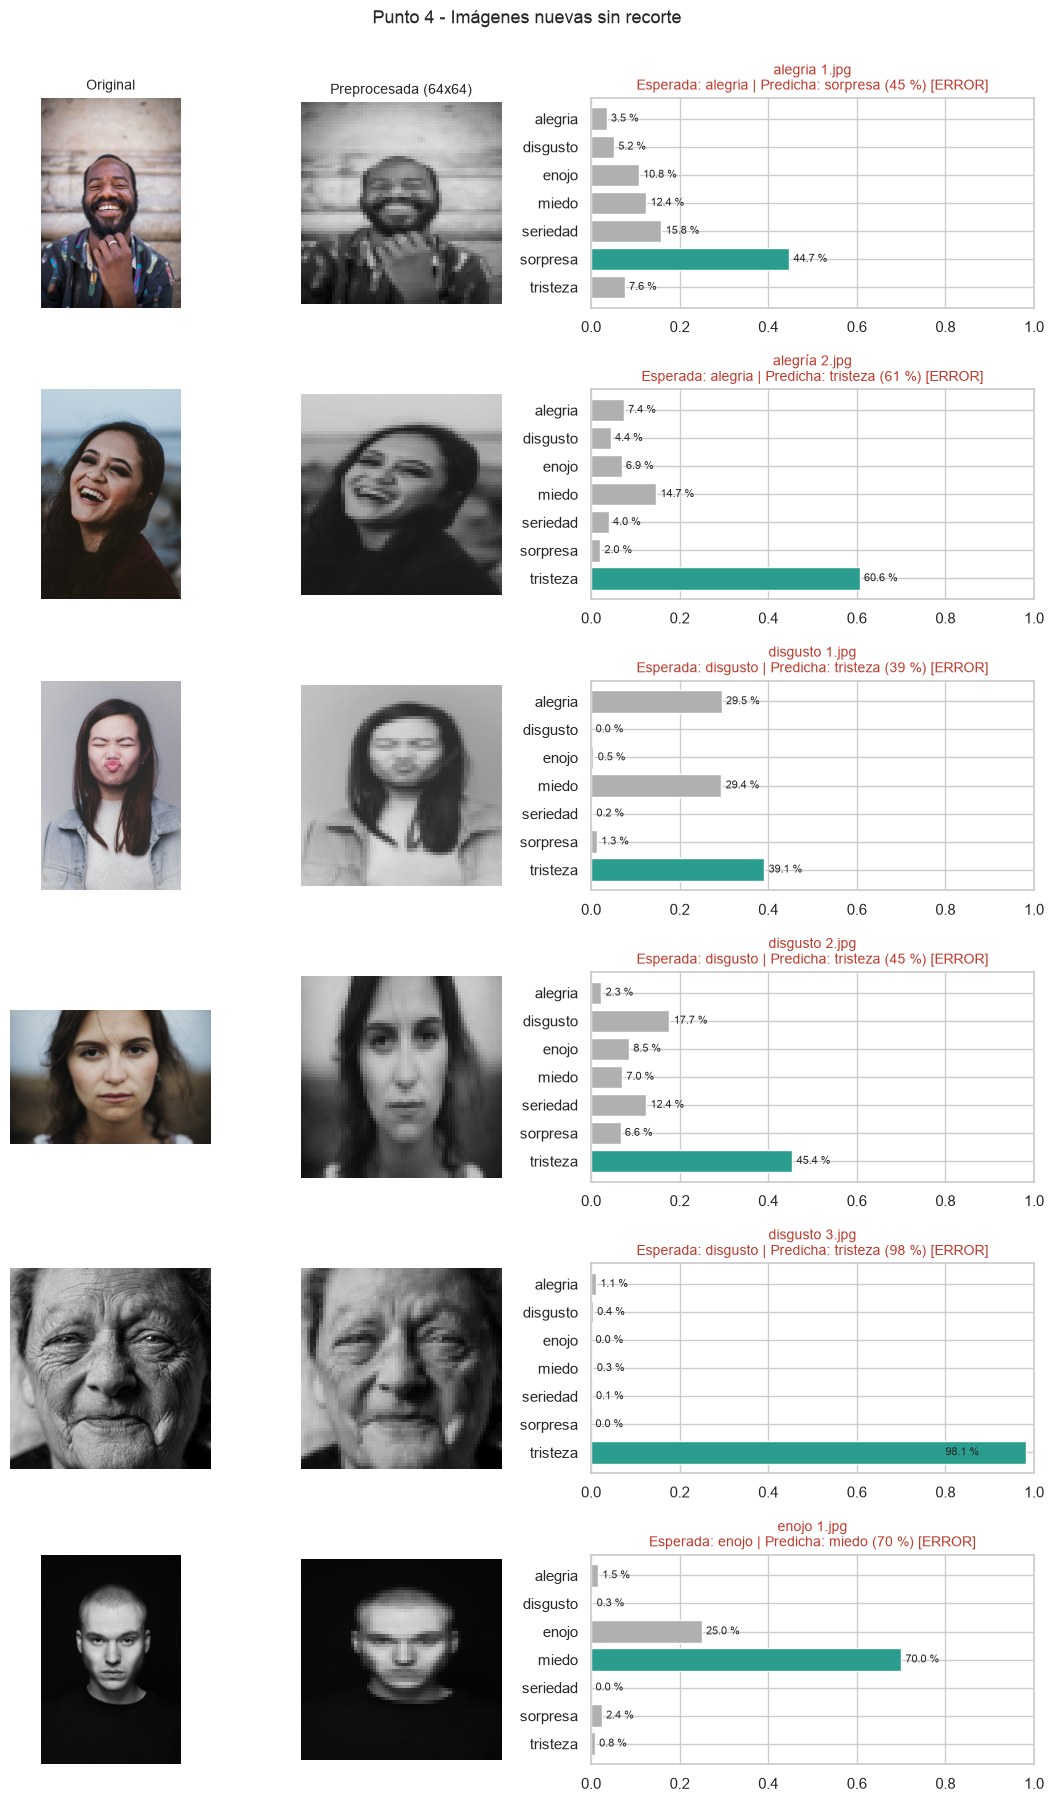

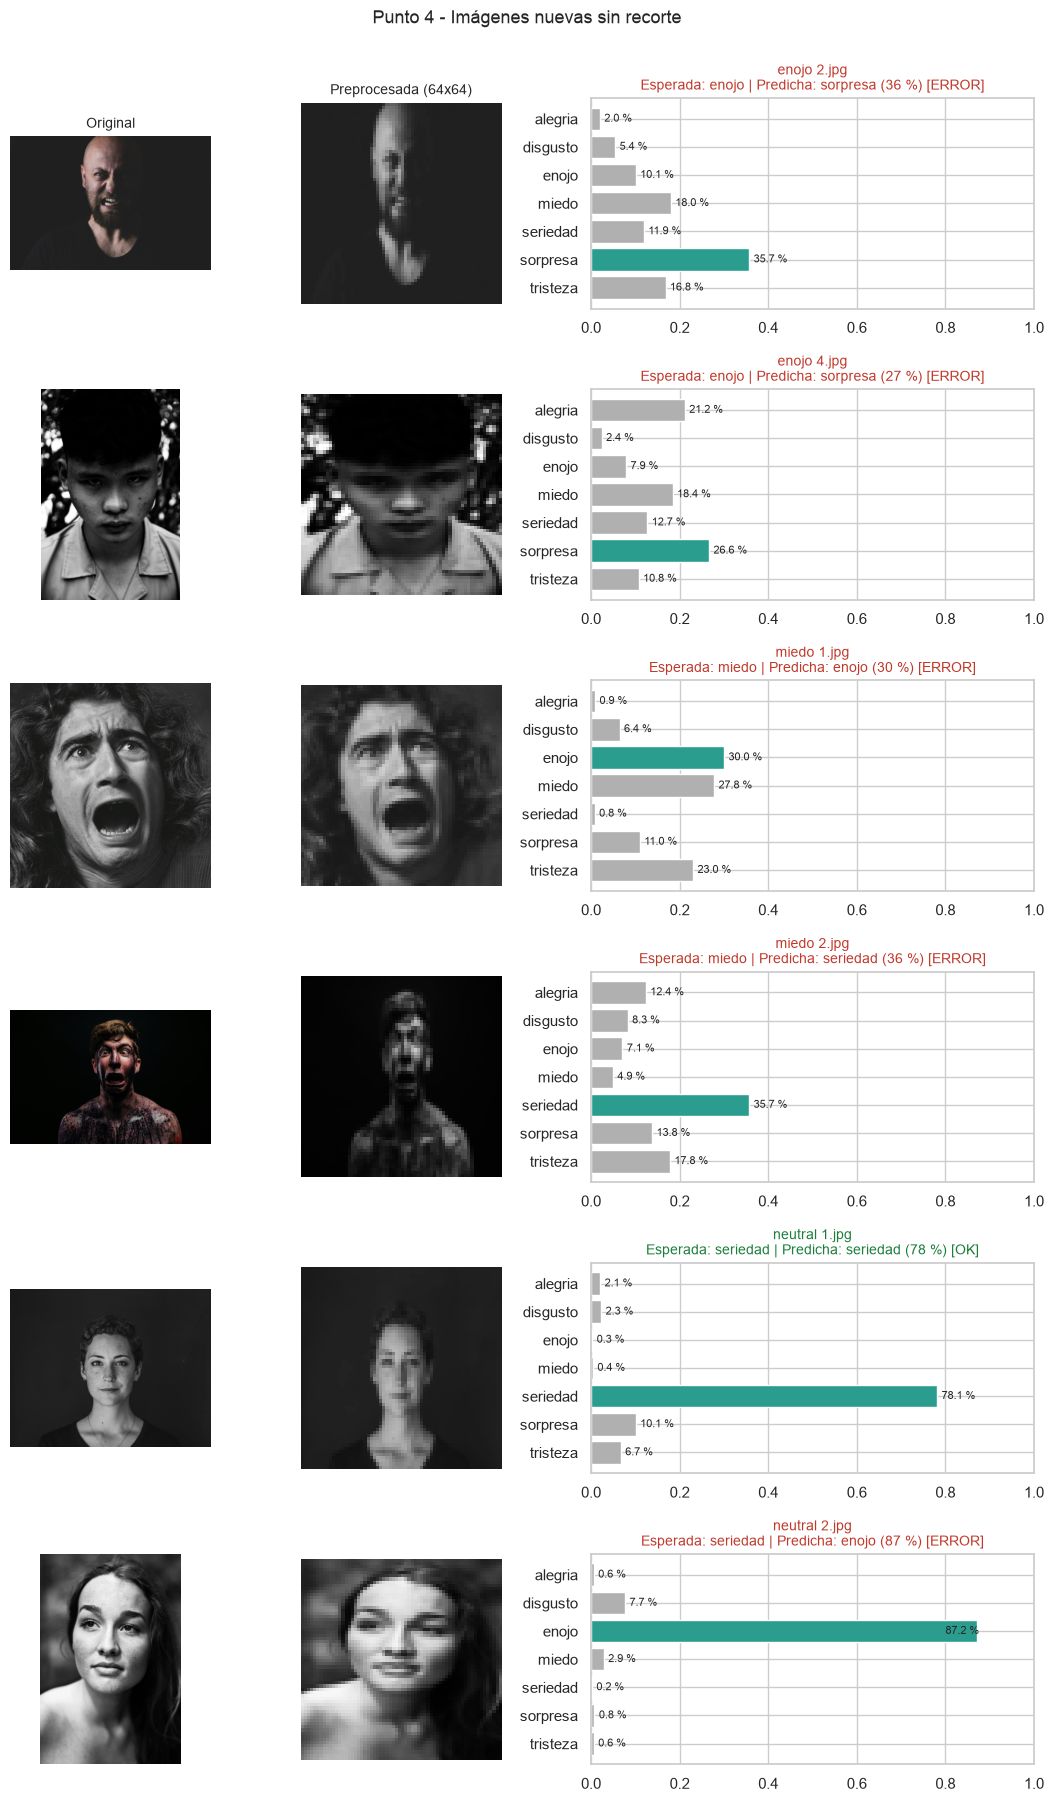

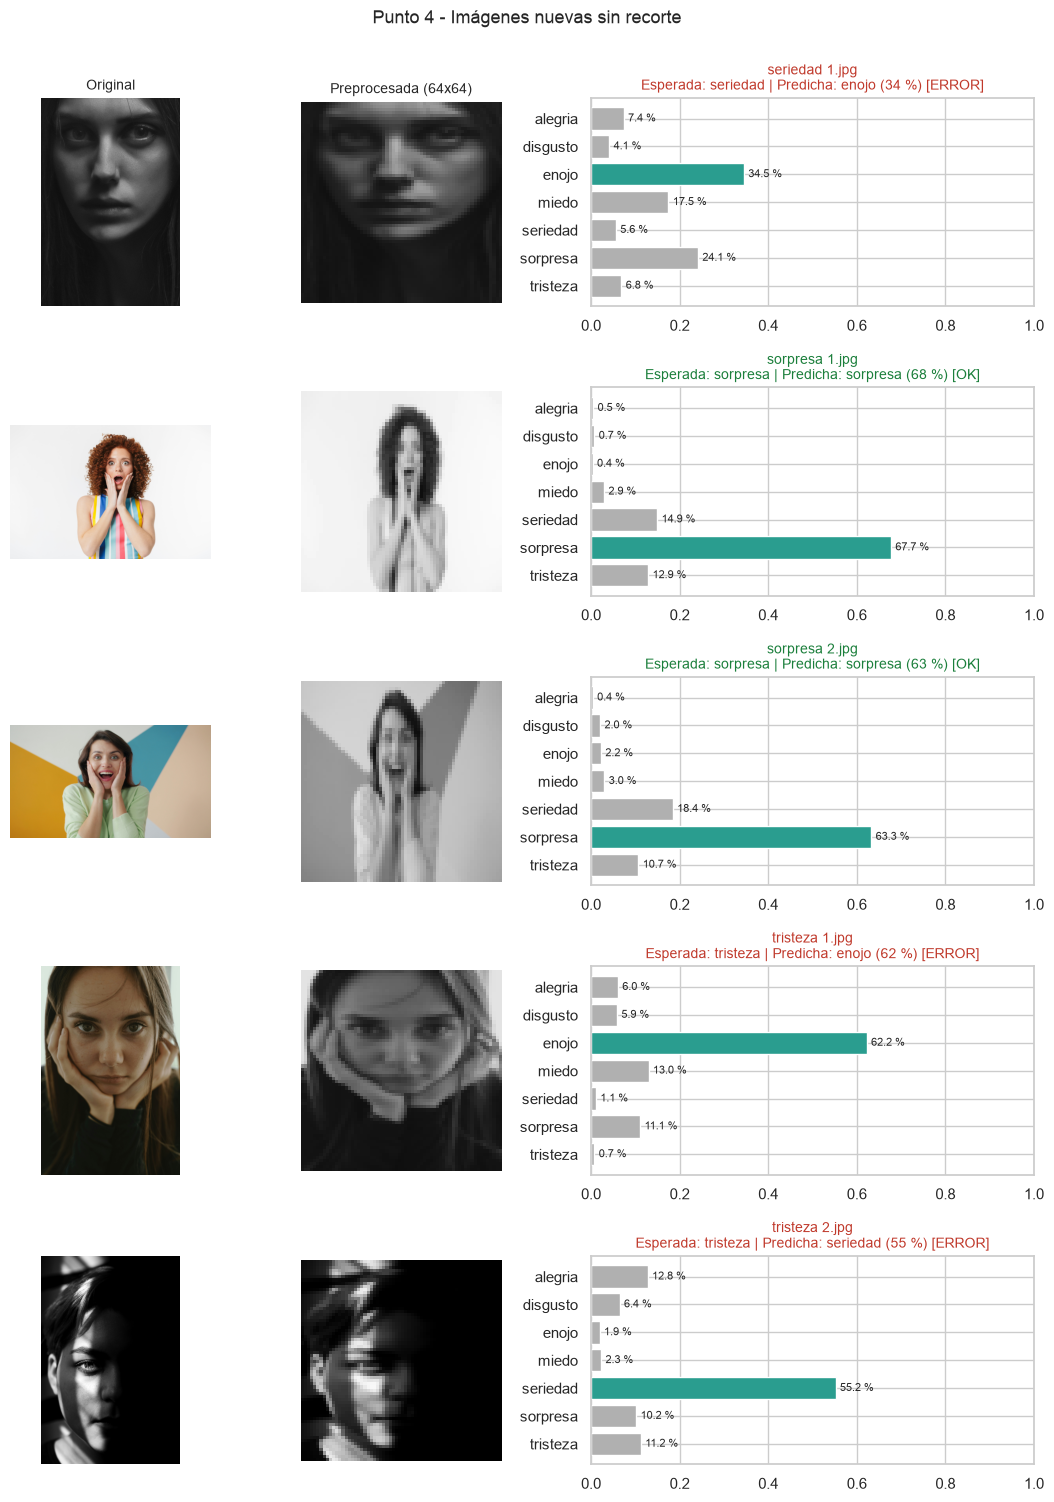

In [14]:
@torch.no_grad()
def predecir_pil(modelo, im_pil):
    modelo.eval()
    prep = base_tf(im_pil)                                    # imagen preprocesada (64x64, gris)
    x = eval_tf(prep).unsqueeze(0).to(DEVICE)
    probs = F.softmax(modelo(x), dim=1)[0].cpu().numpy()
    return probs, prep

def tabla_resultados(items, col_img):
    filas = []
    for d in items:
        probs, _ = predecir_pil(modelo, d[col_img])
        orden = np.argsort(probs)[::-1]
        filas.append({"archivo": d["archivo"], "esperada": d["esperada"], "predicha": CLASES[orden[0]],
                      "confianza": probs[orden[0]], "segunda opción": CLASES[orden[1]], "prob. 2da": probs[orden[1]],
                      "acierto": CLASES[orden[0]] == d["esperada"]})
    return pd.DataFrame(filas)

def mostrar_predicciones(items, paneles, titulo, por_figura=6):
    """paneles: lista de (clave_en_item, titulo) con las imágenes a mostrar antes del preprocesada.
    Luego se agrega siempre la imagen preprocesada y las probabilidades por clase."""
    for ini in range(0, len(items), por_figura):
        lote = items[ini:ini + por_figura]
        ncols = len(paneles) + 2
        fig, axes = plt.subplots(len(lote), ncols, figsize=(3.2 * len(paneles) + 7.5, 3.0 * len(lote)),
                                 gridspec_kw={"width_ratios": [1] * (len(paneles) + 1) + [2.2]}, squeeze=False)
        for fila, d in enumerate(lote):
            probs, prep = predecir_pil(modelo, d["para_modelo"])
            pred = CLASES[int(np.argmax(probs))]
            for col, (clave, tit) in enumerate(paneles):
                axes[fila, col].imshow(d[clave]); axes[fila, col].axis("off")
                axes[fila, col].set_title(tit if fila == 0 else "", fontsize=10)
            axes[fila, len(paneles)].imshow(prep, cmap="gray", vmin=0, vmax=255); axes[fila, len(paneles)].axis("off")
            axes[fila, len(paneles)].set_title("Preprocesada (64x64)" if fila == 0 else "", fontsize=10)
            colores = [COLOR_ACENTO if CLASES[i] == pred else "#b0b0b0" for i in range(len(CLASES))]
            ax = axes[fila, -1]
            ax.barh(CLASES, probs, color=colores); ax.set_xlim(0, 1); ax.invert_yaxis()
            ok = pred == d["esperada"]
            ax.set_title(f"{d['archivo']}\nEsperada: {d['esperada']} | Predicha: {pred} ({100 * probs.max():.0f} %) "
                         f"{'[OK]' if ok else '[ERROR]'}", fontsize=10, color="#1b7f3b" if ok else "#c0392b")
            for i, v in enumerate(probs):
                ax.text(min(v + 0.01, 0.8), i, f"{100 * v:.1f} %", va="center", fontsize=8)
        plt.suptitle(titulo, y=1.0, fontsize=13)
        plt.tight_layout()
        plt.show()

for d in imagenes_nuevas:
    d["para_modelo"] = d["imagen"]       # punto 4: la imagen completa, sin recorte
mostrar_predicciones(imagenes_nuevas, [("imagen", "Original")], "Punto 4 - Imágenes nuevas sin recorte")

In [15]:
res4 = tabla_resultados(imagenes_nuevas, "para_modelo")
display(res4.style.format({"confianza": "{:.1%}", "prob. 2da": "{:.1%}"}))
acc4 = res4["acierto"].mean()
print(f"Aciertos punto 4: {int(res4['acierto'].sum())} de {len(res4)}  (accuracy = {100 * acc4:.1f} %)")
print("\nAciertos por emoción esperada:")
display(res4.groupby("esperada")["acierto"].agg(["sum", "count"]).rename(columns={"sum": "aciertos", "count": "imágenes"}).loc[CLASES])

,archivo,esperada,predicha,confianza,segunda opción,prob. 2da,acierto
0,alegria 1.jpg,alegria,sorpresa,44.7%,seriedad,15.8%,False
1,alegría 2.jpg,alegria,tristeza,60.6%,miedo,14.7%,False
2,disgusto 1.jpg,disgusto,tristeza,39.1%,alegria,29.5%,False
3,disgusto 2.jpg,disgusto,tristeza,45.4%,disgusto,17.7%,False
4,disgusto 3.jpg,disgusto,tristeza,98.1%,alegria,1.1%,False
5,enojo 1.jpg,enojo,miedo,70.0%,enojo,25.0%,False
6,enojo 2.jpg,enojo,sorpresa,35.7%,miedo,18.0%,False
7,enojo 4.jpg,enojo,sorpresa,26.6%,alegria,21.2%,False
8,miedo 1.jpg,miedo,enojo,30.0%,miedo,27.8%,False
9,miedo 2.jpg,miedo,seriedad,35.7%,tristeza,17.8%,False


Aciertos punto 4: 3 de 17  (accuracy = 17.6 %)

Aciertos por emoción esperada:


,aciertos,imágenes
esperada,,
alegria,0,2
disgusto,0,3
enojo,0,3
miedo,0,2
seriedad,1,3
sorpresa,2,2
tristeza,0,2


### 4.3 Conclusiones preliminares

**Resultado.** Con las imágenes completas, sin recorte, el modelo acierta **solo 3 de 17 (17,6 %)**: *neutral 1* (seriedad) y las dos fotos de *sorpresa*. Es un desempeño muy inferior al 82,0 % de validación, y lo más llamativo es que no hay un solo acierto en *alegría*, *disgusto*, *enojo*, *miedo* ni *tristeza*. Con solo 17 imágenes cada una vale casi 6 puntos porcentuales, por lo que conviene leer estos números como una tendencia y no como una medición precisa; de hecho, una versión previa del modelo (entrenada 40 épocas, con peor desempeño en validación) acertó 4 de 17, lo que muestra que la diferencia de una imagen está dentro del ruido.

**Causas probables.** La brecha entre validación y fotos nuevas no se explica por un sobreajuste evidente, sino por un **cambio de dominio** entre los datos de entrenamiento y estas imágenes:

* *Encuadre:* el dataset está formado por recortes de rostros de 100×100 píxeles, mientras que las fotos nuevas son retratos o planos amplios de miles de píxeles en los que la cara ocupa solo una parte. Al forzar la foto completa a 64×64, el rostro queda diminuto y, en las fotos verticales u horizontales, además **deformado** por el cambio de relación de aspecto.
* *Estilo de las fotos:* son imágenes profesionales con iluminación dramática, fuertes sombras, fondos oscuros o blanco y negro artístico, y expresiones **actuadas y exageradas**, distintas de las expresiones más espontáneas que probablemente predominan en el dataset.
* *Confianza mal calibrada:* varios errores se cometen con confianza alta (por ejemplo, *disgusto 3* se predice como *tristeza* con 98,1 % y *neutral 2* como *enojo* con 87,2 %). La probabilidad que entrega *softmax* no es una medida confiable de certeza cuando la imagen está fuera de la distribución de entrenamiento.

La sección siguiente aborda estos problemas de encuadre con un detector de rostros, y permite comprobar cuánto de la brecha se explica por ellos.

---
## 5. Prueba de Imágenes Nuevas con Pre-procesamiento Adicional (1 punto)

Ahora cada imagen pasa primero por un **detector de rostros** (clasificador en cascada de Haar de OpenCV, método de Viola-Jones) que ubica la cara y la **recorta en formato cuadrado 1:1**. Recién después se aplica el mismo preprocesamiento del entrenamiento. Con esto se corrigen dos problemas de la sección 4: la cara ocupa solo una parte de la foto, y forzar una foto no cuadrada a 64×64 la deforma.

### 5.1 Detección y recorte de rostros

Partimos del código sugerido en la consigna, con tres ajustes:

1. **Parámetros adaptativos:** el detector con los valores por defecto (`scaleFactor=1.1, minNeighbors=6, minSize=(30,30)`) no detecta todas las caras, así que probamos una lista de configuraciones **de la más estricta a la más permisiva** y nos quedamos con la primera que encuentra un rostro. Esto mantiene pocos falsos positivos cuando la cara es clara y es más tolerante solo cuando hace falta.
2. **`minSize` relativo** al tamaño de la imagen (un porcentaje del lado menor) en vez de un valor fijo en píxeles, porque nuestras fotos tienen tamaños muy distintos. Además, en las configuraciones permisivas se ecualiza el histograma para mejorar el contraste.
3. **Si hay varias detecciones, se elige la de mayor área** (el rostro principal), en vez de la primera de la lista, lo que descarta falsos positivos pequeños. Al recorte se le agrega un **margen del 15 %** para no cortar frente ni mentón.

In [16]:
cascada = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
assert not cascada.empty(), "No se pudo cargar el clasificador Haar de OpenCV."

# (scaleFactor, minNeighbors, minSize como fracción del lado menor, ecualizar histograma)  - de estricta a permisiva
CONFIGS_DETECCION = [(1.10, 6, 0.05, False),
                     (1.10, 4, 0.05, False),
                     (1.05, 4, 0.05, True),
                     (1.05, 3, 0.12, True),
                     (1.03, 2, 0.12, True)]
MARGEN = 0.15

def detectar_y_recortar(im_pil, margen=MARGEN):
    rgb = np.array(im_pil)
    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    alto, ancho = gris.shape
    for k, (scale, vecinos, frac, ecualizar) in enumerate(CONFIGS_DETECCION):
        g = cv2.equalizeHist(gris) if ecualizar else gris
        lado_min = max(20, int(frac * min(alto, ancho)))
        caras = cascada.detectMultiScale(g, scaleFactor=scale, minNeighbors=vecinos, minSize=(lado_min, lado_min))
        if len(caras) > 0:
            x, y, w, h = max(caras, key=lambda c: c[2] * c[3])          # rostro principal = mayor área
            cx, cy = x + w // 2, y + h // 2
            mitad = int(max(w, h) * (1 + margen) / 2)
            x1, y1 = max(cx - mitad, 0), max(cy - mitad, 0)
            x2, y2 = min(cx + mitad, ancho), min(cy + mitad, alto)
            con_caja = rgb.copy()
            for (fx, fy, fw, fh) in caras:
                cv2.rectangle(con_caja, (fx, fy), (fx + fw, fy + fh), (255, 0, 0), max(2, ancho // 200))
            return {"detectado": True, "config": k, "n_caras": len(caras), "con_caja": Image.fromarray(con_caja),
                    "recorte": Image.fromarray(rgb[y1:y2, x1:x2])}
    # Sin detección: se usa un recorte cuadrado centrado como respaldo (y se informa)
    lado = min(alto, ancho); x1, y1 = (ancho - lado) // 2, (alto - lado) // 2
    return {"detectado": False, "config": None, "n_caras": 0, "con_caja": im_pil,
            "recorte": Image.fromarray(rgb[y1:y1 + lado, x1:x1 + lado])}

for d in imagenes_nuevas:
    r = detectar_y_recortar(d["imagen"])
    d["detectado"], d["config_det"], d["n_caras"] = r["detectado"], r["config"], r["n_caras"]
    d["con_caja"], d["recorte"] = r["con_caja"], r["recorte"]

det = pd.DataFrame([{"archivo": d["archivo"], "rostro detectado": d["detectado"], "configuración usada": d["config_det"],
                     "caras encontradas": d["n_caras"], "recorte (px)": f"{d['recorte'].size[0]}x{d['recorte'].size[1]}"}
                    for d in imagenes_nuevas])
display(det)
print(f"Rostros detectados: {int(det['rostro detectado'].sum())} de {len(det)}")

,archivo,rostro detectado,configuración usada,caras encontradas,recorte (px)
0,alegria 1.jpg,True,0,1,326x326
1,alegría 2.jpg,True,1,1,474x474
2,disgusto 1.jpg,True,0,1,348x348
3,disgusto 2.jpg,True,0,1,606x590
4,disgusto 3.jpg,True,0,2,1002x988
5,enojo 1.jpg,True,0,1,448x448
6,enojo 2.jpg,True,0,1,342x342
7,enojo 4.jpg,True,0,1,576x576
8,miedo 1.jpg,True,0,1,754x754
9,miedo 2.jpg,True,0,1,276x276


Rostros detectados: 17 de 17


### 5.2 Predicción sobre los rostros recortados

Para cada imagen se muestra la **original con la detección**, el **recorte 1:1**, la **imagen preprocesada** (mismas transformaciones del entrenamiento), el **score por clase**, la **clase esperada** y la **clase inferida** por el modelo.

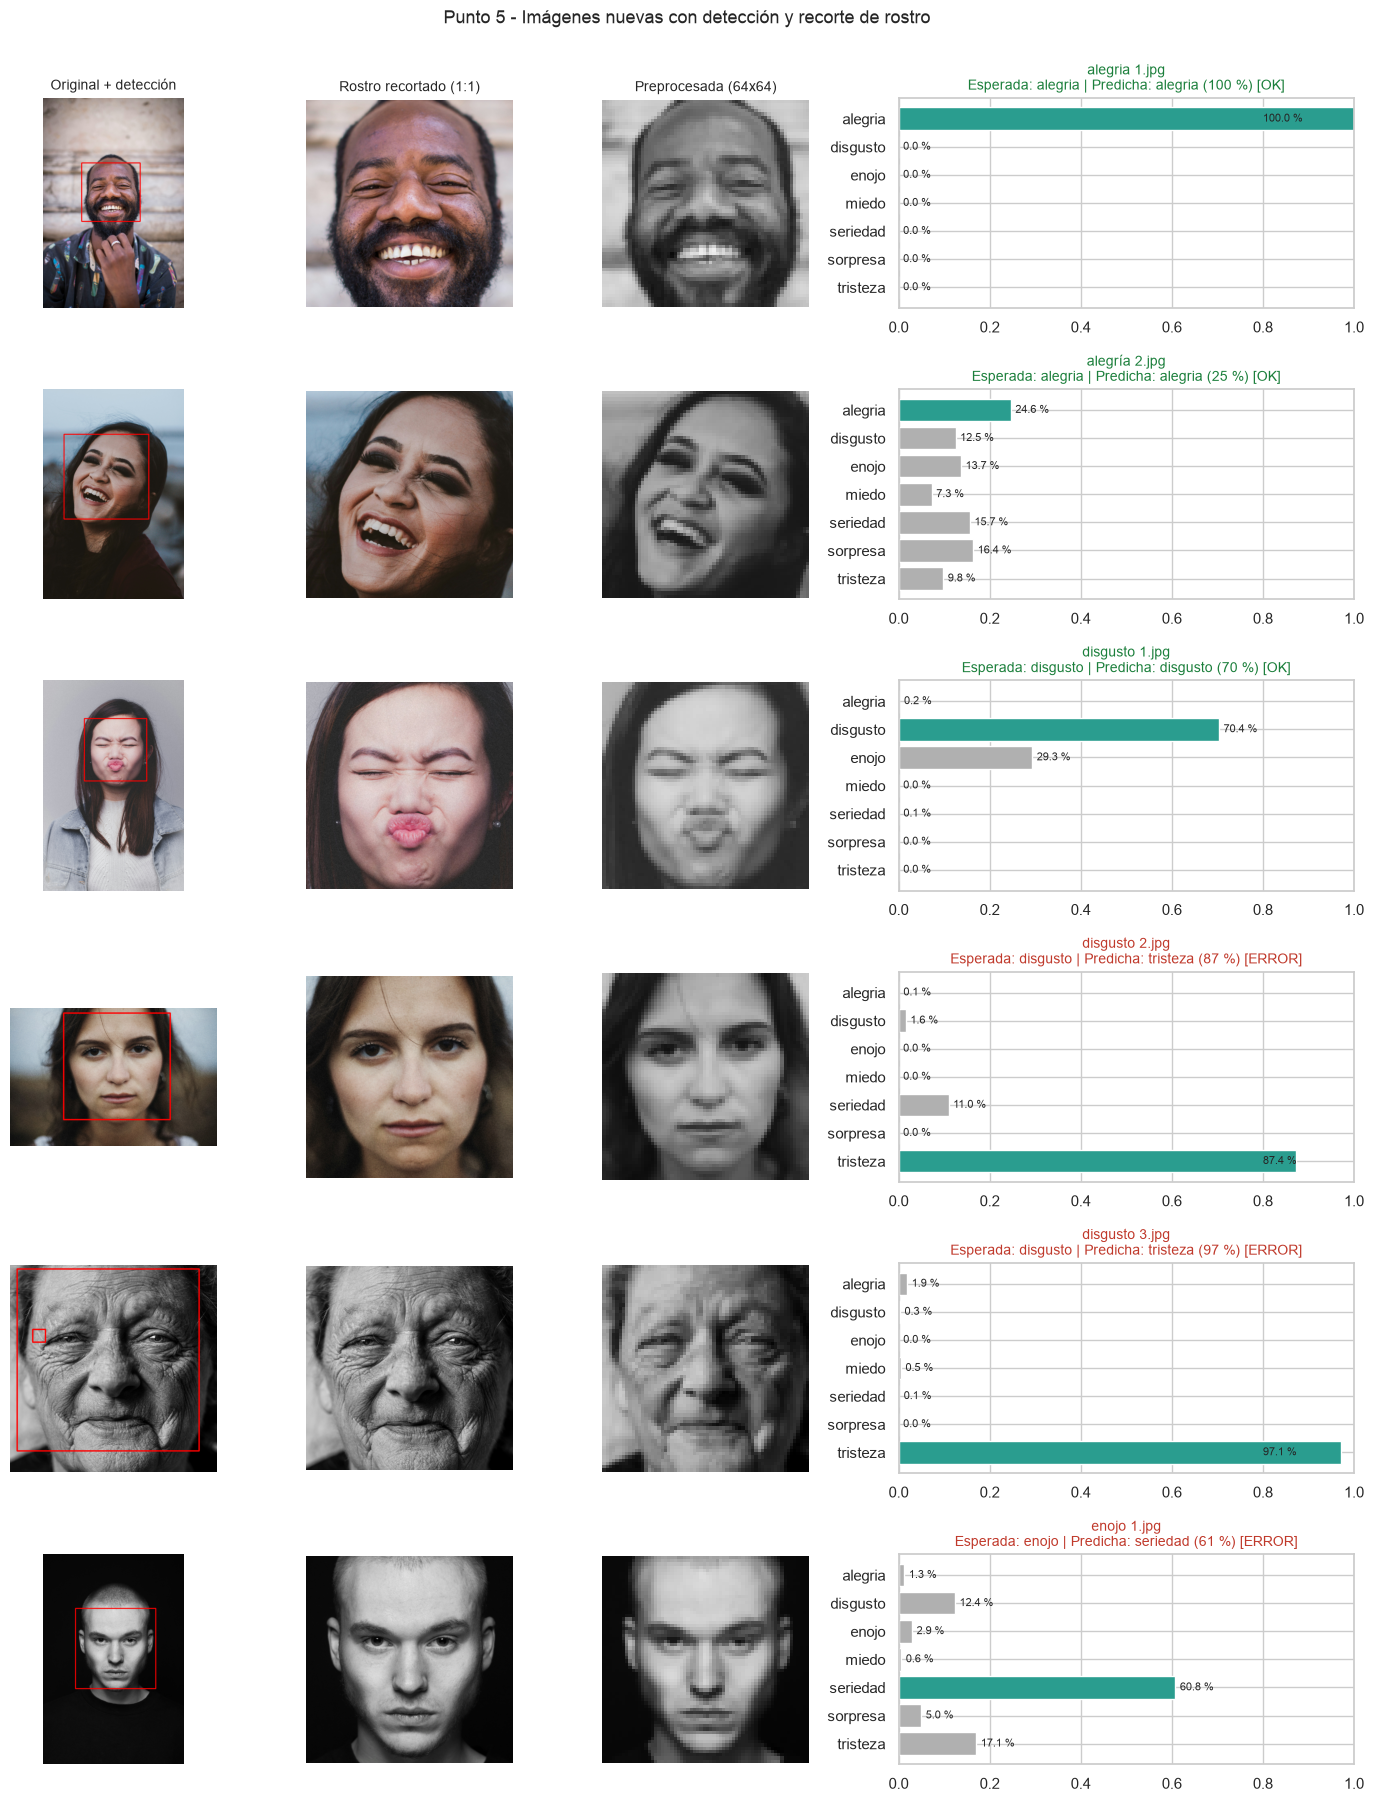

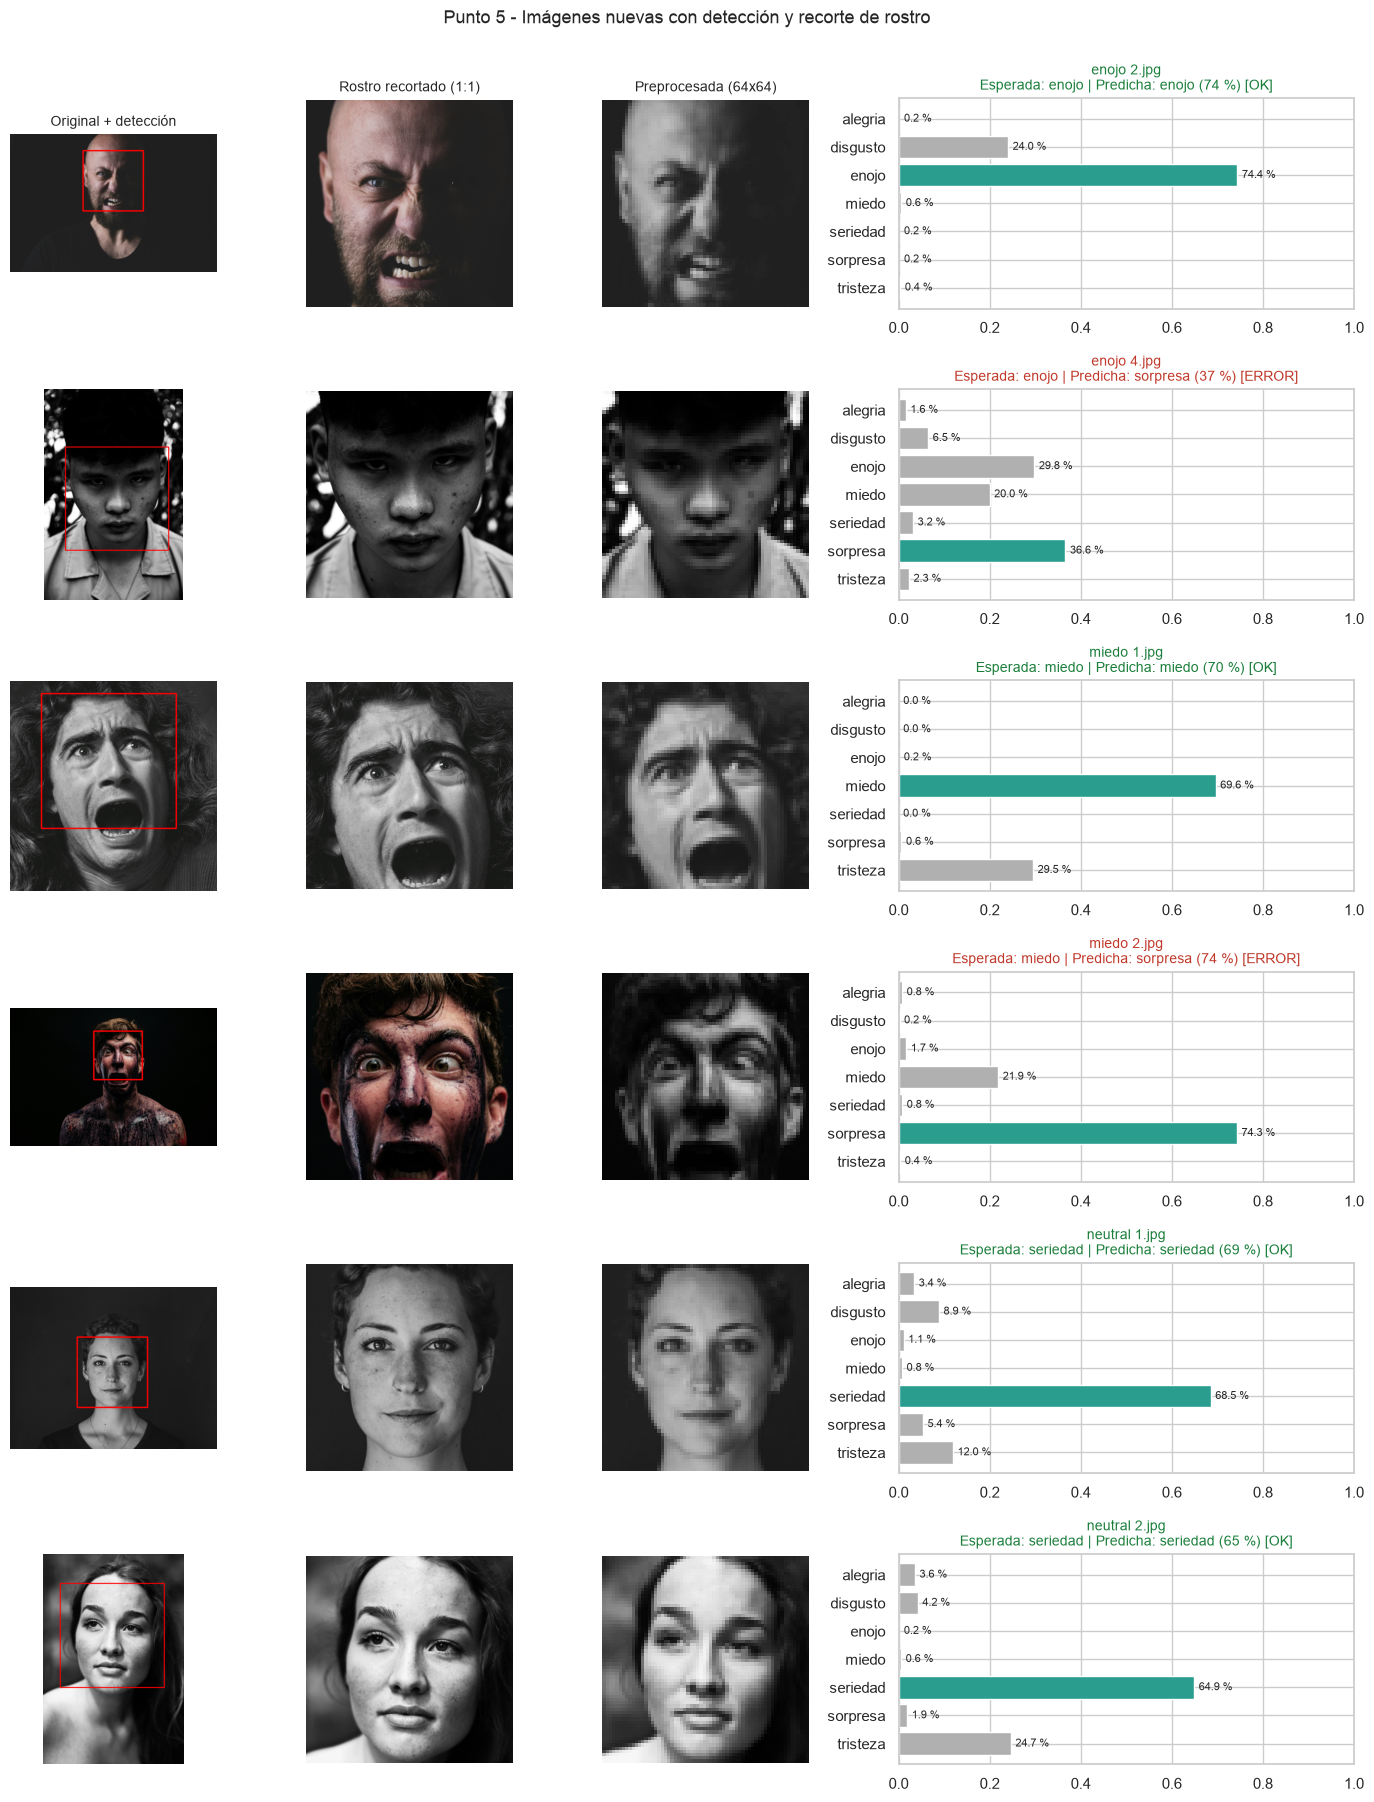

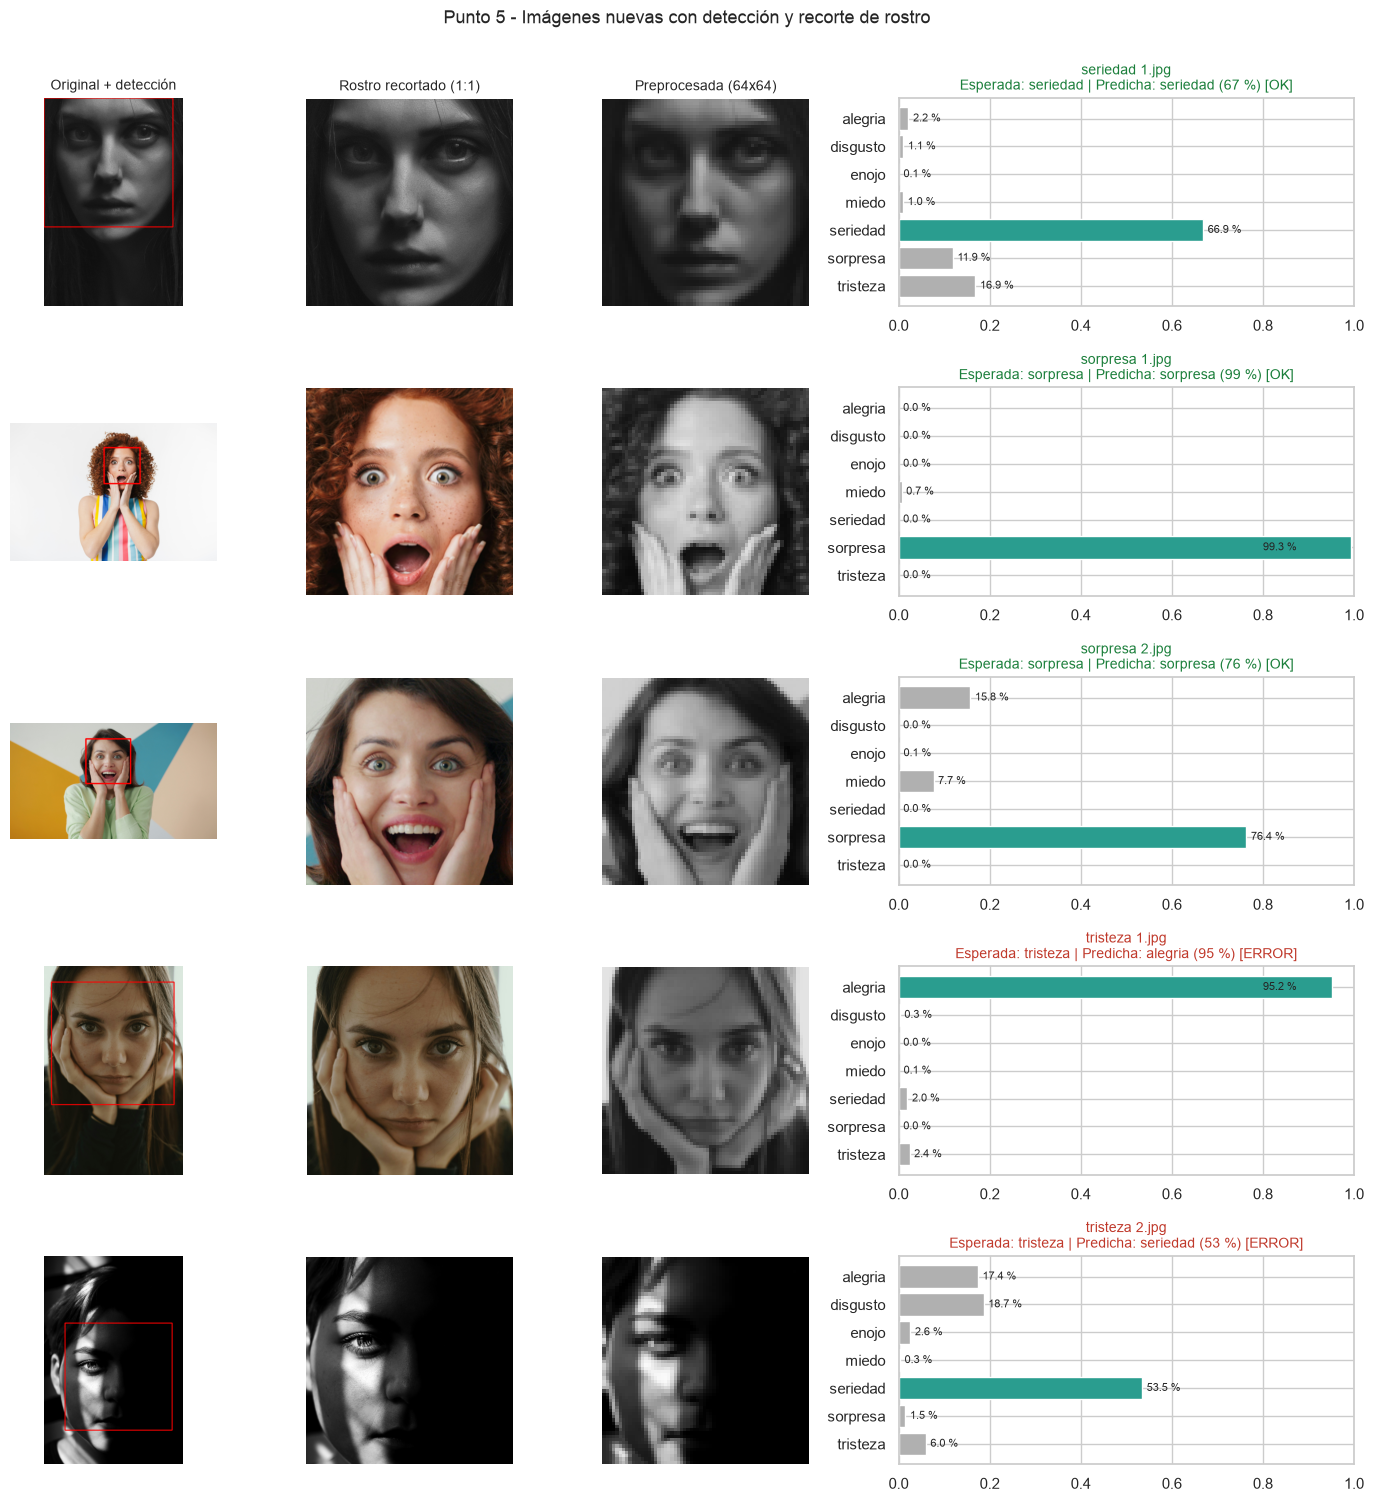

In [17]:
for d in imagenes_nuevas:
    d["para_modelo"] = d["recorte"]          # punto 5: el recorte del rostro
mostrar_predicciones(imagenes_nuevas, [("con_caja", "Original + detección"), ("recorte", "Rostro recortado (1:1)")],
                     "Punto 5 - Imágenes nuevas con detección y recorte de rostro")

### 5.3 Comparación con el punto 4 y análisis de errores

,archivo,esperada,P4 predicha,P4 conf.,P5 predicha,P5 conf.,rostro detectado,cambio
0,alegria 1.jpg,alegria,sorpresa,44.7%,alegria,100.0%,True,mejoró
1,alegría 2.jpg,alegria,tristeza,60.6%,alegria,24.6%,True,mejoró
2,disgusto 1.jpg,disgusto,tristeza,39.1%,disgusto,70.4%,True,mejoró
3,disgusto 2.jpg,disgusto,tristeza,45.4%,tristeza,87.4%,True,igual
4,disgusto 3.jpg,disgusto,tristeza,98.1%,tristeza,97.1%,True,igual
5,enojo 1.jpg,enojo,miedo,70.0%,seriedad,60.8%,True,igual
6,enojo 2.jpg,enojo,sorpresa,35.7%,enojo,74.4%,True,mejoró
7,enojo 4.jpg,enojo,sorpresa,26.6%,sorpresa,36.6%,True,igual
8,miedo 1.jpg,miedo,enojo,30.0%,miedo,69.6%,True,mejoró
9,miedo 2.jpg,miedo,seriedad,35.7%,sorpresa,74.3%,True,igual


Accuracy sin recorte (punto 4): 17.6 %  (3/17)
Accuracy con recorte (punto 5): 58.8 %  (10/17)
Cambios al agregar el recorte: {'igual': 10, 'mejoró': 7}


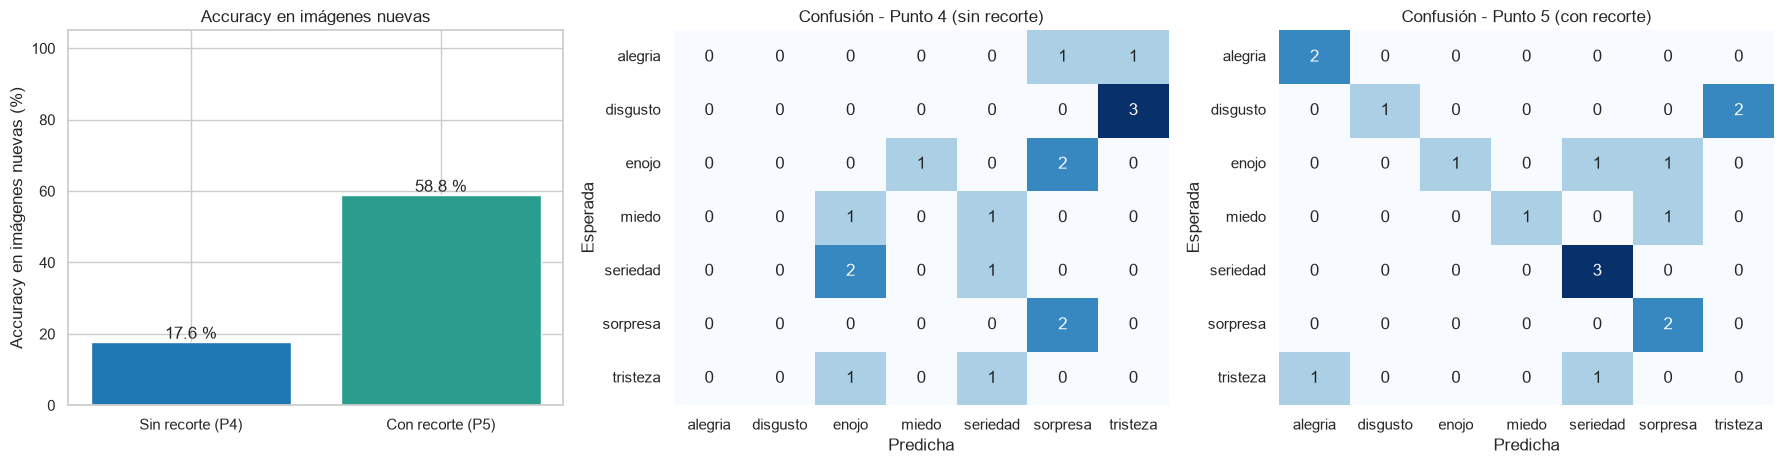


Errores del punto 5 (con la segunda opción más probable, útil para ver mezcla de emociones):


,archivo,esperada,predicha,confianza,segunda opción,prob. 2da
3,disgusto 2.jpg,disgusto,tristeza,87.4%,seriedad,11.0%
4,disgusto 3.jpg,disgusto,tristeza,97.1%,alegria,1.9%
5,enojo 1.jpg,enojo,seriedad,60.8%,tristeza,17.1%
7,enojo 4.jpg,enojo,sorpresa,36.6%,enojo,29.8%
9,miedo 2.jpg,miedo,sorpresa,74.3%,miedo,21.9%
15,tristeza 1.jpg,tristeza,alegria,95.2%,tristeza,2.4%
16,tristeza 2.jpg,tristeza,seriedad,53.5%,disgusto,18.7%


In [18]:
res5 = tabla_resultados(imagenes_nuevas, "para_modelo")
acc5 = res5["acierto"].mean()

comp = pd.DataFrame({
    "archivo": res4["archivo"], "esperada": res4["esperada"],
    "P4 predicha": res4["predicha"], "P4 conf.": res4["confianza"],
    "P5 predicha": res5["predicha"], "P5 conf.": res5["confianza"],
    "rostro detectado": [d["detectado"] for d in imagenes_nuevas],
})
comp["cambio"] = np.select([(~res4["acierto"]) & res5["acierto"], res4["acierto"] & (~res5["acierto"])],
                           ["mejoró", "empeoró"], default="igual")
display(comp.style.format({"P4 conf.": "{:.1%}", "P5 conf.": "{:.1%}"}))

print(f"Accuracy sin recorte (punto 4): {100 * acc4:.1f} %  ({int(res4['acierto'].sum())}/{len(res4)})")
print(f"Accuracy con recorte (punto 5): {100 * acc5:.1f} %  ({int(res5['acierto'].sum())}/{len(res5)})")
print("Cambios al agregar el recorte:", {k: int(v) for k, v in comp["cambio"].value_counts().items()})

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].bar(["Sin recorte (P4)", "Con recorte (P5)"], [100 * acc4, 100 * acc5], color=[COLOR_TRAIN, COLOR_ACENTO])
for i, v in enumerate([100 * acc4, 100 * acc5]):
    axes[0].text(i, v + 1, f"{v:.1f} %", ha="center")
axes[0].set_ylim(0, 105); axes[0].set_ylabel("Accuracy en imágenes nuevas (%)"); axes[0].set_title("Accuracy en imágenes nuevas")
for ax, res, titulo in zip(axes[1:], [res4, res5], ["Confusión - Punto 4 (sin recorte)", "Confusión - Punto 5 (con recorte)"]):
    cm_n = confusion_matrix(res["esperada"], res["predicha"], labels=CLASES)
    sns.heatmap(cm_n, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASES, yticklabels=CLASES, ax=ax)
    ax.set_title(titulo); ax.set_xlabel("Predicha"); ax.set_ylabel("Esperada")
plt.tight_layout()
plt.show()

print("\nErrores del punto 5 (con la segunda opción más probable, útil para ver mezcla de emociones):")
display(res5[~res5["acierto"]].drop(columns="acierto").style.format({"confianza": "{:.1%}", "prob. 2da": "{:.1%}"}))

### 5.4 Análisis de errores y conclusiones finales

**Efecto del recorte.** Detectar y recortar el rostro **más que triplica el desempeño**: el accuracy sobre las imágenes nuevas pasa de **17,6 % (3/17) a 58,8 % (10/17)**. Siete imágenes mejoraron (*alegría 1* y *2*, *disgusto 1*, *enojo 2*, *miedo 1*, *neutral 2* y *seriedad 1*), ninguna empeoró y diez quedaron igual (tres aciertos que se mantuvieron y siete errores que persistieron). Este resultado confirma que gran parte de la brecha de la sección 4 se debía al **encuadre**: al recortar, la cara ocupa todo el cuadro, se evita la deformación por relación de aspecto y el modelo ve algo mucho más parecido a su dataset de entrenamiento. La detección funcionó en las 17 fotos y no generó recortes erróneos: en *disgusto 3* aparecieron dos detecciones, pero la regla de quedarse con la de mayor área descartó el falso positivo pequeño; y *seriedad 1* (un primer plano muy cerrado) solo fue detectada con la configuración más permisiva, lo que muestra la utilidad de la lista de parámetros escalonada. Por emoción, el recorte dejó *alegría* (2/2), *seriedad* (3/3) y *sorpresa* (2/2) perfectas, *miedo* 1/2, *disgusto* 1/3, *enojo* 1/3 y *tristeza* 0/2.

**Análisis de los siete errores restantes.**

* *Miedo 2 → sorpresa (74 %), segunda opción miedo (22 %).* Es la confusión clásica entre ambas emociones: ojos muy abiertos y boca abierta. También en validación el 12 % de los *miedo* se predicen como *sorpresa*. El modelo no se equivoca de familia expresiva: distingue "ojos y boca muy abiertos" de las demás, pero no logra separar bien las dos emociones que los comparten.
* *Enojo 4 → sorpresa (37 %), segunda opción enojo (30 %).* Mirada fija con el ceño fruncido en una foto de alto contraste. La diferencia entre la primera opción (sorpresa) y la segunda (enojo, la clase correcta) es de apenas siete puntos, es decir que el modelo duda entre ambas: un caso genuinamente ambiguo para este modelo.
* *Enojo 1 → seriedad (61 %).* Es una mirada intensa y fría con la boca cerrada y poca tensión en la mitad inferior de la cara; el modelo interpreta la falta de movimiento facial como una expresión neutra. Ilustra por qué *seriedad* actúa como clase refugio.
* *Disgusto 2 y 3 → tristeza (87 % y 97 %).* En ambos casos la expresión es sutil: *disgusto 2* muestra la boca cerrada y las cejas apenas fruncidas, y *disgusto 3* es un rostro de una persona mayor con la comisura de la boca hacia abajo. Las arrugas y los rasgos caídos propios de la edad pueden leerse como tristeza (esta explicación es una hipótesis nuestra que no verificamos). Además, *disgusto* es la clase más débil del modelo incluso en validación (F1 0,49), de modo que no sorprende que sea la que peor generaliza. También hay que reconocer que las etiquetas de estas fotos las asignamos nosotros según la búsqueda que hicimos y que no son una verdad de referencia anotada: la expresión de *disgusto 3*, en particular, es discutible incluso para una persona.
* *Tristeza 1 → alegría (95 %).* El error más claro y más confiado. La persona tiene las manos sobre las mejillas y la cabeza inclinada, con la boca cerrada y relajada. Una posible explicación es que la pose con las manos en la cara aparece en el dataset asociada a otras emociones, pero no lo comprobamos.
* *Tristeza 2 → seriedad (54 %), segunda opción disgusto (19 %).* Una parte importante del rostro está en sombra, incluida casi toda la zona de la boca, un rasgo muy informativo para la tristeza; sin él, el modelo cae en la clase neutra.

**Patrones generales.** (1) Los errores se concentran en **emociones que comparten rasgos** (miedo/sorpresa, disgusto/tristeza/seriedad, enojo/seriedad), los mismos pares que ya aparecían en la matriz de confusión de validación. (2) Las emociones **expresadas con claridad y de forma intensa** (*sorpresa 1* y *2*, *alegría 1*, *enojo 2*, *miedo 1*) se reconocen bien, mientras que las **sutiles o mezcladas** fallan. (3) La mayoría de los errores ocurre entre emociones cercanas; la excepción más notable es *tristeza 1 → alegría*, un error entre emociones opuestas y, además, con muy alta confianza. (4) Algunos aciertos son frágiles: *alegría 2* se acierta por muy poco (24,6 % de confianza), con una risa muy amplia y la cabeza inclinada. (5) El modelo tiene una confianza excesiva en varios de sus errores, algo que se podría mitigar con técnicas de calibración o *label smoothing*.

**Conclusiones finales.**

* Construimos una CNN desde cero (2,2 millones de parámetros) que logra **82,0 % de accuracy y 0,744 de F1 macro** en validación, a pesar de un desbalance de clases de 17 a 1. La combinación de escala de grises, normalización con estadísticas de *train*, *augmentation*, pérdida ponderada y selección por F1 macro resultó eficaz.
* El **desbalance** se compensó bien en *miedo* (F1 0,64 con solo 281 imágenes de entrenamiento) pero con un costo visible en *disgusto*, donde ganamos *recall* a cambio de *precision*.
* **El mayor problema no fue la arquitectura sino la distribución de los datos.** El mismo modelo pasa de 82 % en validación a 18 % en fotos nuevas sin recorte, y a 59 % con recorte. La diferencia entre ambas situaciones muestra que un buen resultado en validación no garantiza buen desempeño en datos reales si estos difieren en encuadre, resolución, iluminación o estilo de expresión, y que **el preprocesamiento en inferencia debe replicar las condiciones del entrenamiento**.
* Incluso con recorte quedan 7 errores de 17, concentrados en expresiones sutiles o mezcladas. Con una muestra de solo 17 imágenes, de las cuales algunas tienen etiquetas discutibles, estos números son indicativos y no deben tomarse como una estimación precisa del desempeño real.
* *Posibles mejoras:* entrenar con más variedad de estilos (más *augmentation* de iluminación y sombras), aplicar el mismo recorte facial al entrenar para eliminar el cambio de dominio, usar un muestreo balanceado o *focal loss* para mejorar la *precision* de *disgusto*, calibrar las probabilidades, y, si el enunciado lo permitiera, partir de un modelo preentrenado. También ayudaría tener un conjunto de test separado de validación.

---
## Referencias

* Documentación de PyTorch: https://docs.pytorch.org/docs/stable/
* Documentación de `torchvision.transforms`: https://docs.pytorch.org/vision/stable/transforms.html
* Viola, P. y Jones, M. (2001). *Rapid Object Detection using a Boosted Cascade of Simple Features.* CVPR. Implementación en OpenCV: https://docs.opencv.org/4.x/db/d28/tutorial_cascade_classifier.html
* Documentación de scikit-learn (métricas): https://scikit-learn.org/stable/modules/model_evaluation.html
* Ioffe, S. y Szegedy, C. (2015). *Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift.*
* Kingma, D. y Ba, J. (2015). *Adam: A Method for Stochastic Optimization.*
* Imágenes nuevas (puntos 4 y 5): fotos de uso libre de Pexels (https://www.pexels.com), Unsplash (https://unsplash.com) y Pixabay (https://pixabay.com).